# Observing labour.csv

In [ ]:
%pip install missingno


[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [214]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import missingno as msno
import seaborn as sns

data = pd.read_csv("../data/raw/labour.csv")
# house = pd.read_csv("../data/raw/household.csv")
h=data.head()
display(h)
print("Shape:", data.shape)
print("Indicators number:", len(data["Indicator"].unique()))

/var/folders/d3/_3prq75j4zs7ww42zcnxc6bw0000gn/T/ipykernel_29157/2441239528.py:8: DtypeWarning: Columns (7,8,14) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv("../data/raw/labour.csv")


,Indicator,Region,Availability of seasonal adjustment,Economic activity type,Breakdown category,Breakdown,Frequency,Indicator update date,Indicator next update date,Unit of measure,...,2026-Q1,2026-M01,2026-M02,2026-M03,2026-Q2,2026-M04,2026-M05,2026-M06,2026-M07,2026-M08
0,Average monthly salary (nominal) of a full-tim...,Ukraine,Not applicable,"Libraries, archives, museums and other cultura...",Sex,Female,Quarterly,NaN,NaN,UAH,...,13417.0,NaN,NaN,NaN,15558.0,NaN,NaN,NaN,NaN,NaN
1,Average monthly salary (nominal) of a full-tim...,Ukraine,Not applicable,Warehousing and support activities for transpo...,Sex,Total,Quarterly,NaN,NaN,UAH,...,30982.0,NaN,NaN,NaN,32602.0,NaN,NaN,NaN,NaN,NaN
2,Average monthly salary (nominal) of a full-tim...,Ukraine,Not applicable,Land transport and transport via pipelines,Sex,Male,Quarterly,NaN,NaN,UAH,...,25707.0,NaN,NaN,NaN,27748.0,NaN,NaN,NaN,NaN,NaN
3,Average monthly salary (nominal) of a full-tim...,Ukraine,Not applicable,Air transport,Sex,Male,Quarterly,NaN,NaN,UAH,...,64174.0,NaN,NaN,NaN,71005.0,NaN,NaN,NaN,NaN,NaN
4,Average monthly salary (nominal) of a full-tim...,Ukraine,Not applicable,Scientific research and development,Sex,Female,Annual,NaN,NaN,UAH,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Shape: (24059, 468)
Indicators number: 37


Indicator                                  0
Region                                     0
Availability of seasonal adjustment        0
Economic activity type                     0
Breakdown category                         0
                                       ...  
2026-M04                               21736
2026-M05                               21736
2026-M06                               21736
2026-M07                               21736
2026-M08                               21736
Length: 468, dtype: int64

Index(['Indicator', 'Region', 'Availability of seasonal adjustment',
       'Economic activity type', 'Breakdown category', 'Breakdown',
       'Frequency', 'Indicator update date', 'Indicator next update date',
       'Unit of measure',
       ...
       '2026-Q1', '2026-M01', '2026-M02', '2026-M03', '2026-Q2', '2026-M04',
       '2026-M05', '2026-M06', '2026-M07', '2026-M08'],
      dtype='object', length=468)
Emp cols ['Indicator', 'Region', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025']


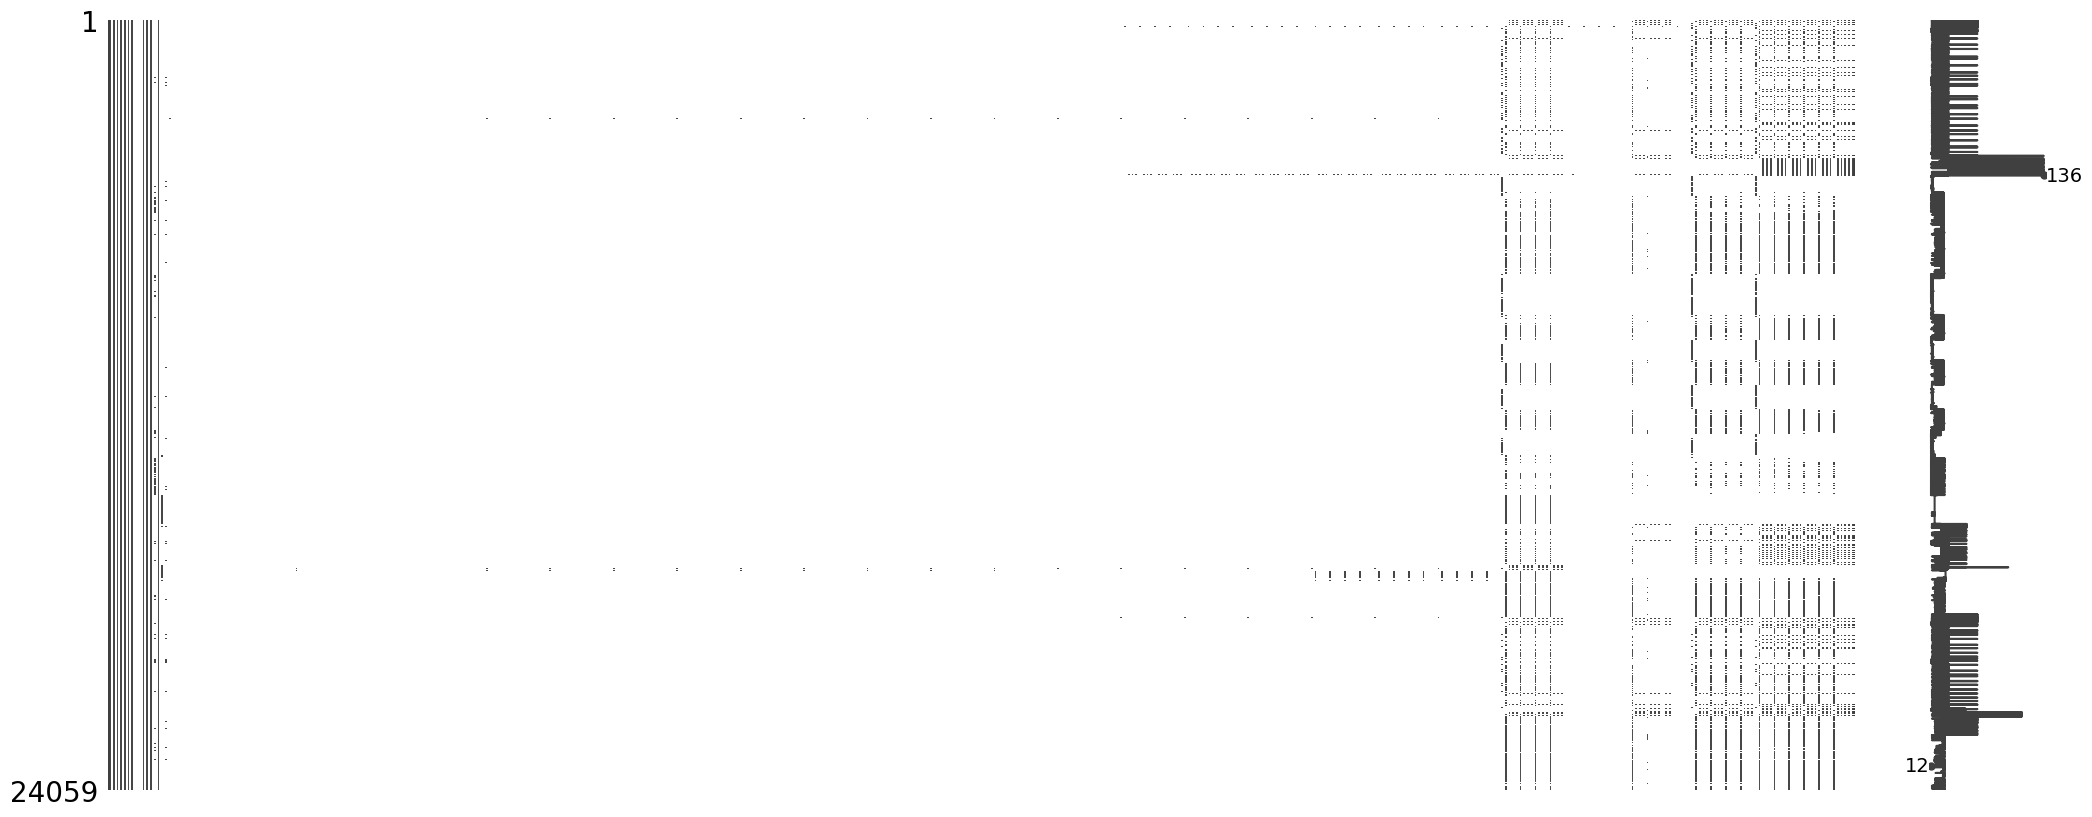

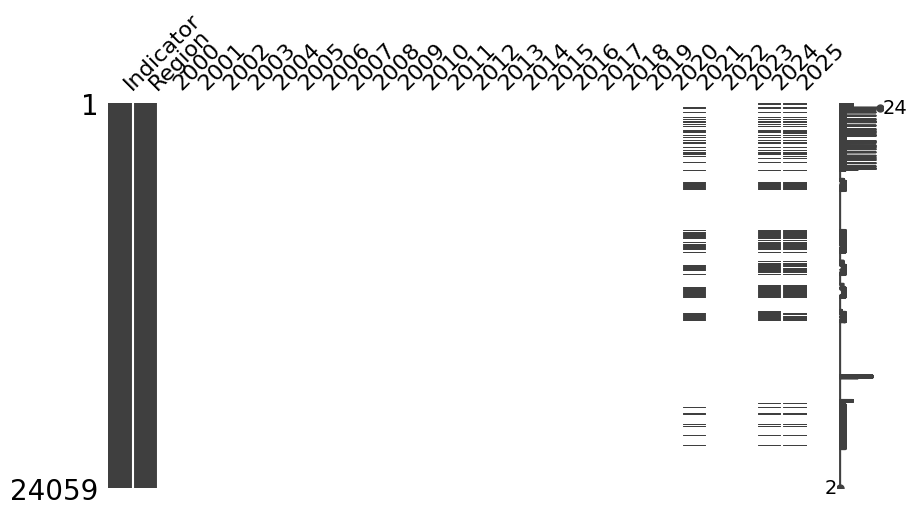

In [14]:
display(data.isna().sum())
msno.matrix(data)
# Select columns related to employment/wages
print(data.columns)
employment_cols = [col for col in data.columns if ('Indicator' == col or 'Region'== col or '20' in col) and '-' not in col]
print("Emp cols", employment_cols)
# Plot missingness matrix only for these columns
msno.matrix(data[employment_cols], figsize=(10, 5))
plt.show()

Annual cols ['Indicator', 'Region', 'Availability of seasonal adjustment', 'Economic activity type', 'Breakdown category', 'Breakdown', 'Frequency', 'Indicator update date', 'Indicator next update date', 'Unit of measure', 'Scaling', 'Decimals displayed', 'Observation flag', 'Dataset notes', 'Timeseries notes', 'Observation notes', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025']


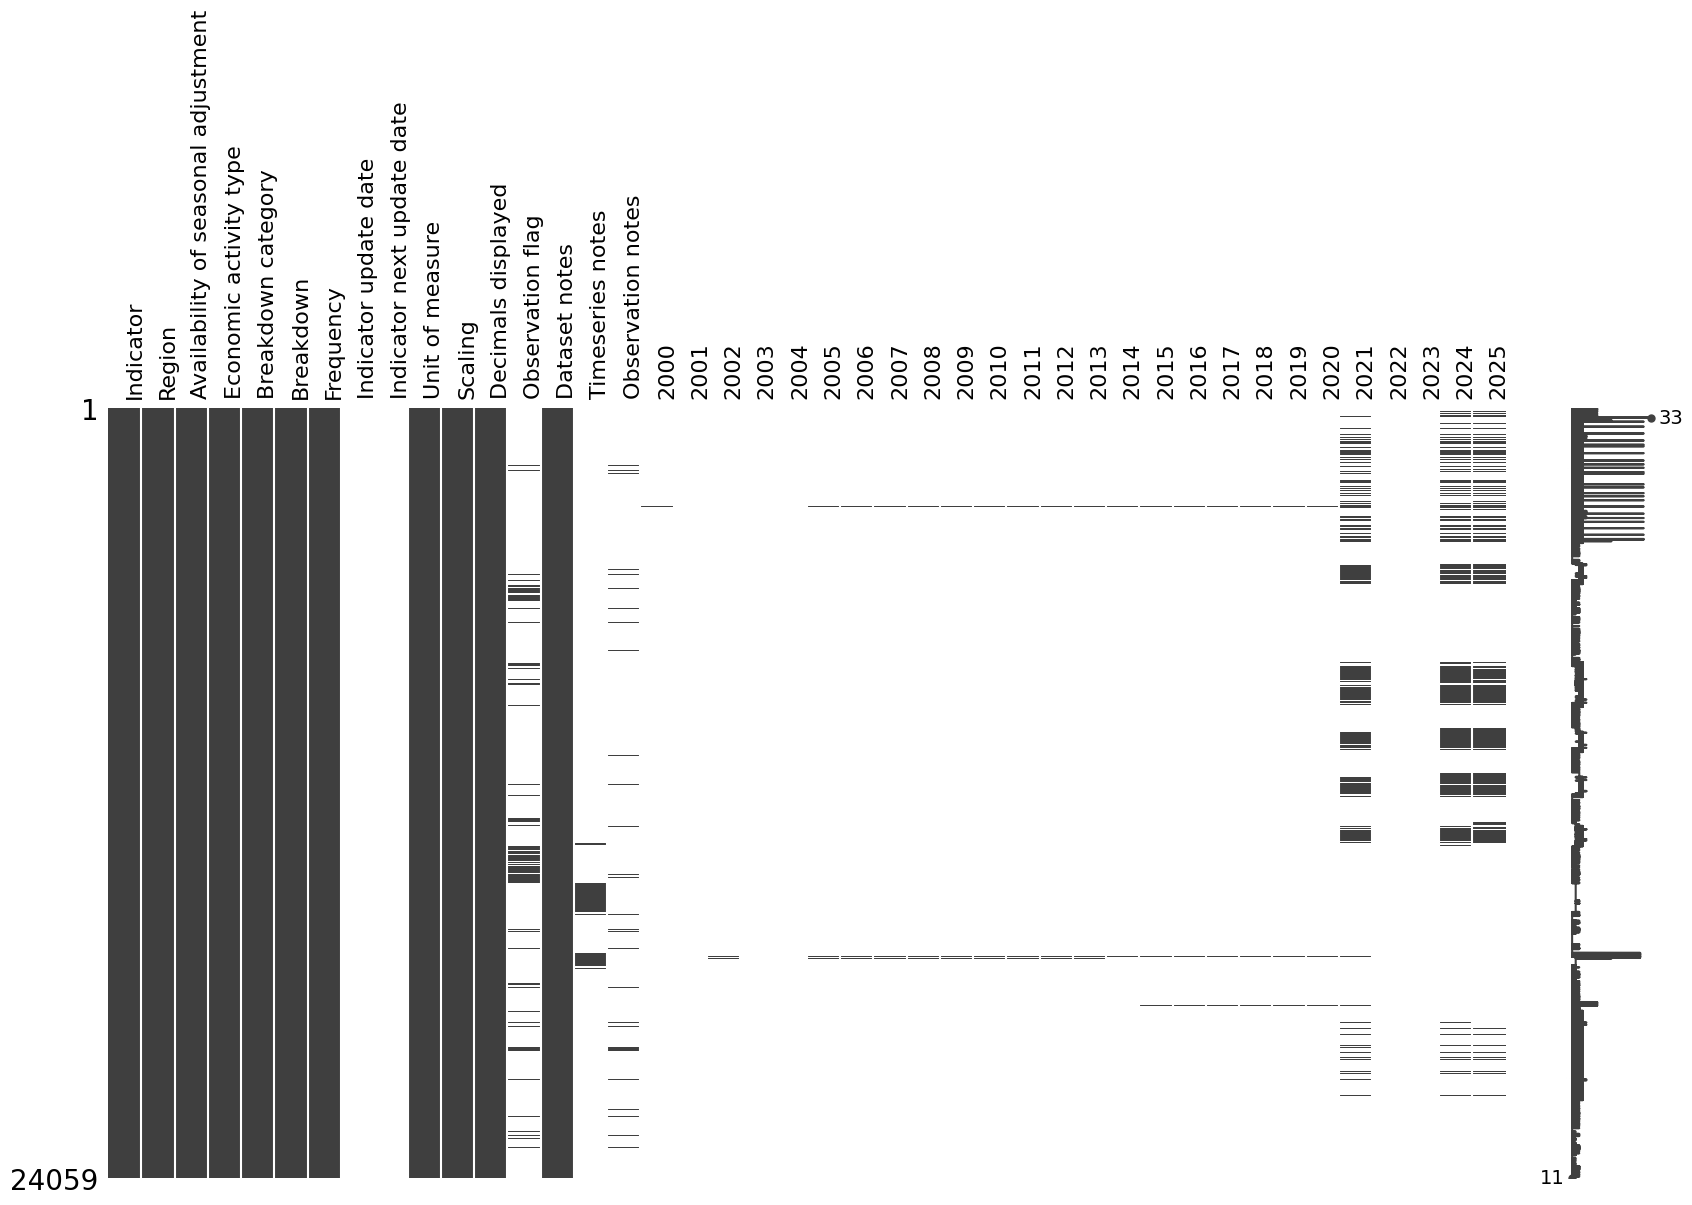

In [30]:

annual_col = [col for col in data.columns if '-' not in col]
print("Annual cols", annual_col)
# Plot missingness matrix only for these columns
msno.matrix(data[annual_col], figsize=(20, 10))
plt.xticks(rotation=90)
plt.show()

# data["Time period"] = pd.to_numeric(data["Time period"])
# print("Time period SORTED")
# display(data[annual_col].sort_values("Time period", ascending=True))

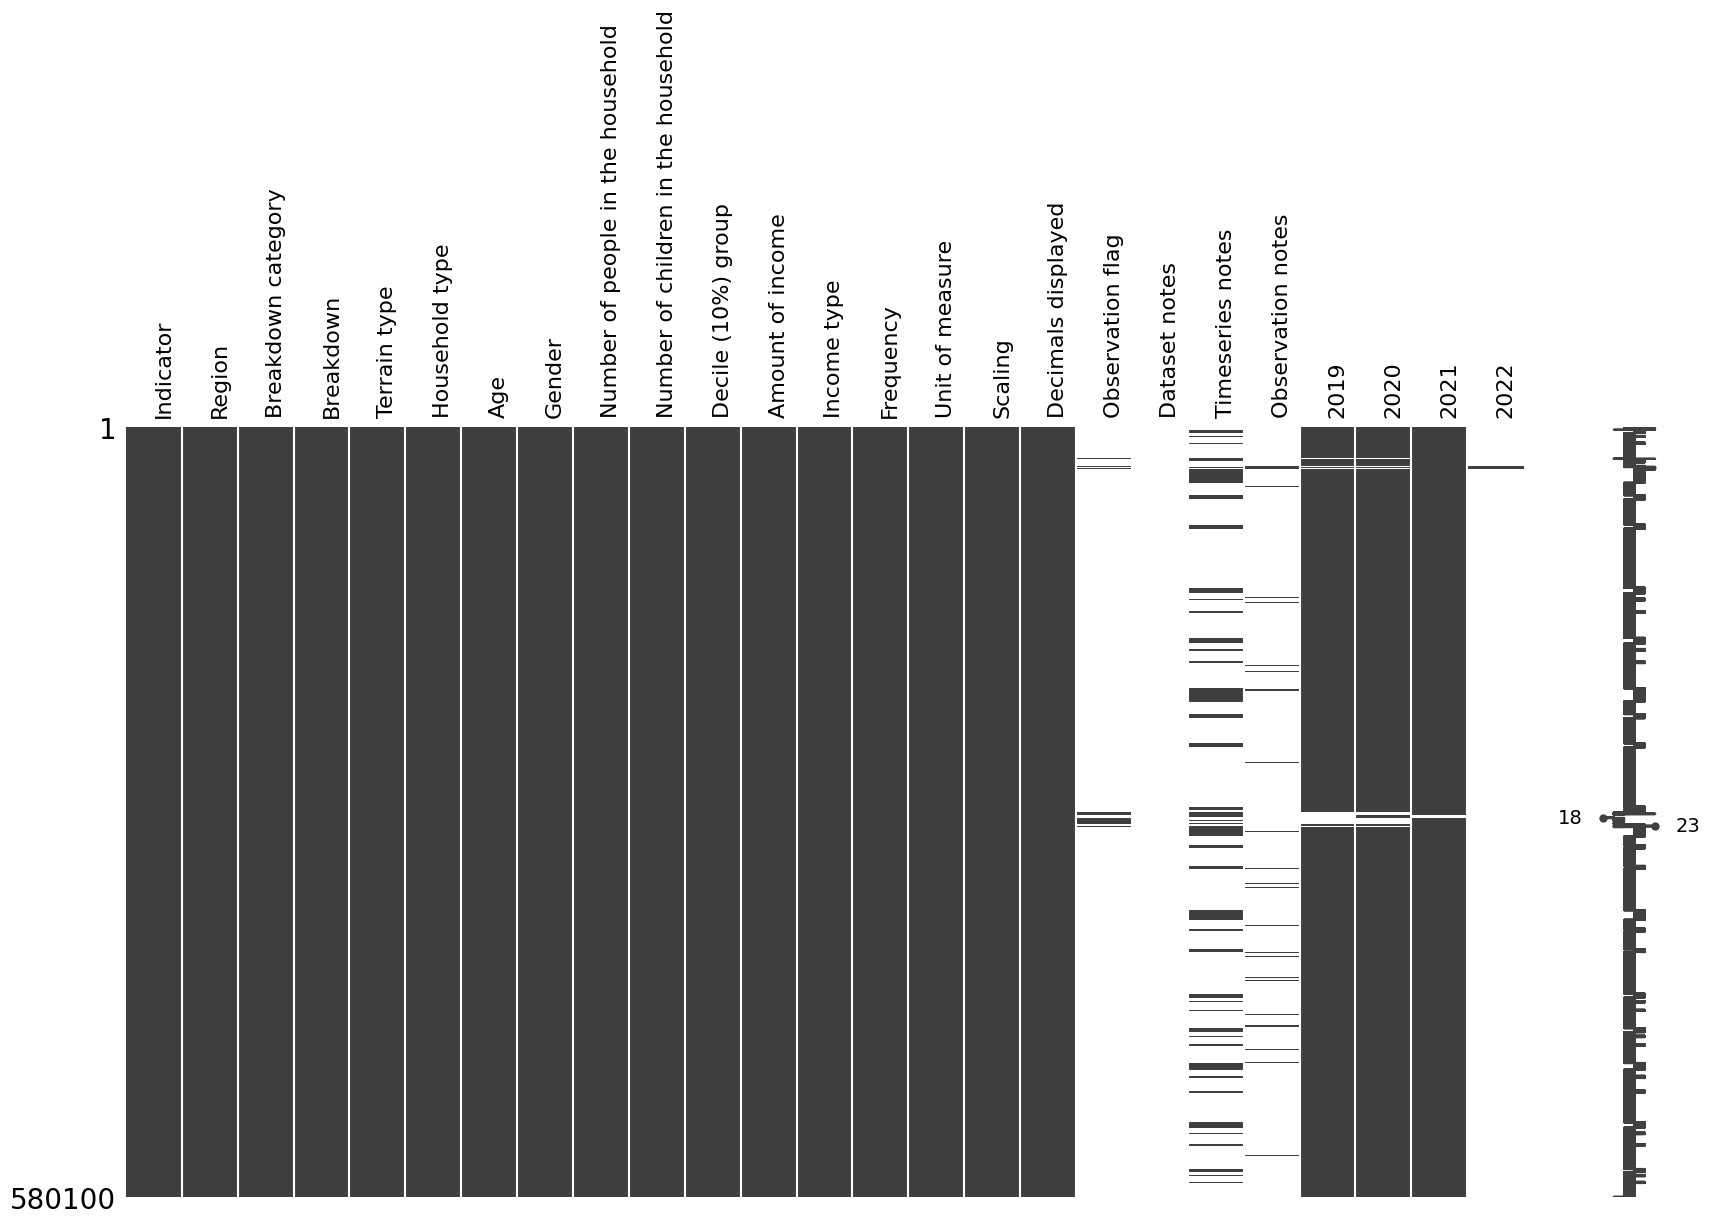

In [32]:
msno.matrix(house, figsize=(20, 10))
plt.xticks(rotation=90)
plt.show()


Annual cols ['Indicator', 'Region', 'Availability of seasonal adjustment', 'Economic activity type', 'Breakdown category', 'Breakdown', 'Frequency', 'Indicator update date', 'Indicator next update date', 'Unit of measure', 'Scaling', 'Decimals displayed', 'Observation flag', 'Dataset notes', 'Timeseries notes', 'Observation notes', '2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025']


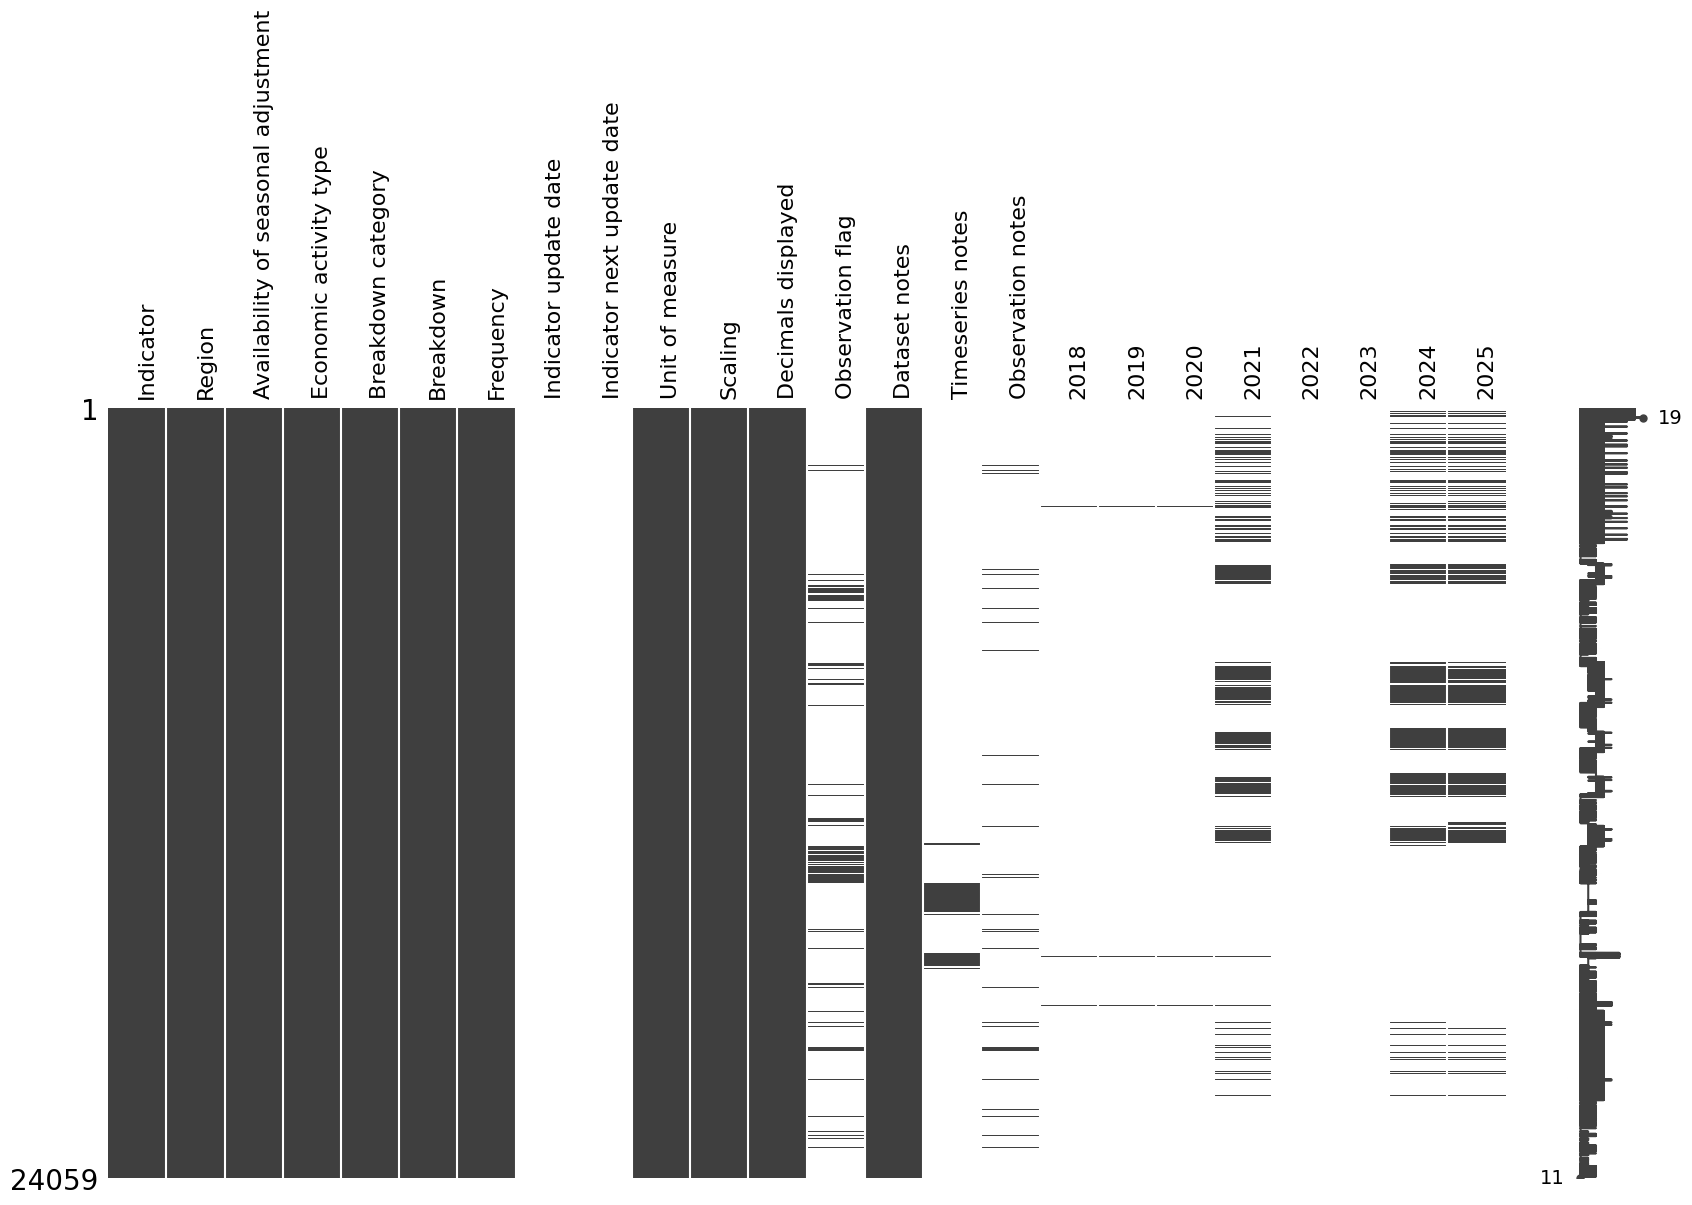

Number of missing values for 2019 out of 24059 rows  23946 present values :  113
Number of missing values for 2020 out of 24059 rows  23946 present values :  113
Number of missing values for 2021 out of 24059 rows  19035 present values :  5024
Number of missing values for 2022 out of 24059 rows  24032 present values :  27
Number of missing values for 2023 out of 24059 rows  24032 present values :  27
Number of missing values for 2024 out of 24059 rows  18474 present values :  5585
Number of missing values for 2025 out of 24059 rows  18409 present values :  5650


In [47]:
annual_2018_25 = [col for col in data[annual_col].columns if ('20' not in col or ('20' in col and int(col)>2017))]
print("Annual cols", annual_2018_25)
# Plot missingness matrix only for these columns
msno.matrix(data[annual_2018_25], figsize=(20, 10))
plt.xticks(rotation=90)
plt.show()
print("Number of missing values for 2019 out of 24059 rows ",data["2019"].isna().sum(), "present values : " ,data.shape[0] - data["2019"].isna().sum())
print("Number of missing values for 2020 out of 24059 rows ",data["2020"].isna().sum(), "present values : " ,data.shape[0] - data["2020"].isna().sum())
print("Number of missing values for 2021 out of 24059 rows ",data["2021"].isna().sum(), "present values : " ,data.shape[0] - data["2021"].isna().sum())
print("Number of missing values for 2022 out of 24059 rows ",data["2022"].isna().sum(), "present values : " ,data.shape[0] - data["2022"].isna().sum())
print("Number of missing values for 2023 out of 24059 rows ",data["2023"].isna().sum(), "present values : " ,data.shape[0] - data["2023"].isna().sum())
print("Number of missing values for 2024 out of 24059 rows ",data["2024"].isna().sum(), "present values : " ,data.shape[0] - data["2024"].isna().sum())
print("Number of missing values for 2025 out of 24059 rows ",data["2025"].isna().sum(), "present values : " ,data.shape[0] - data["2025"].isna().sum())

Shape (5149, 476)


/var/folders/d3/_3prq75j4zs7ww42zcnxc6bw0000gn/T/ipykernel_29157/3969887617.py:1: DtypeWarning: Columns (8) have mixed types. Specify dtype option on import or set low_memory=False.
  cons = pd.read_csv("../data/raw/consumer.csv")


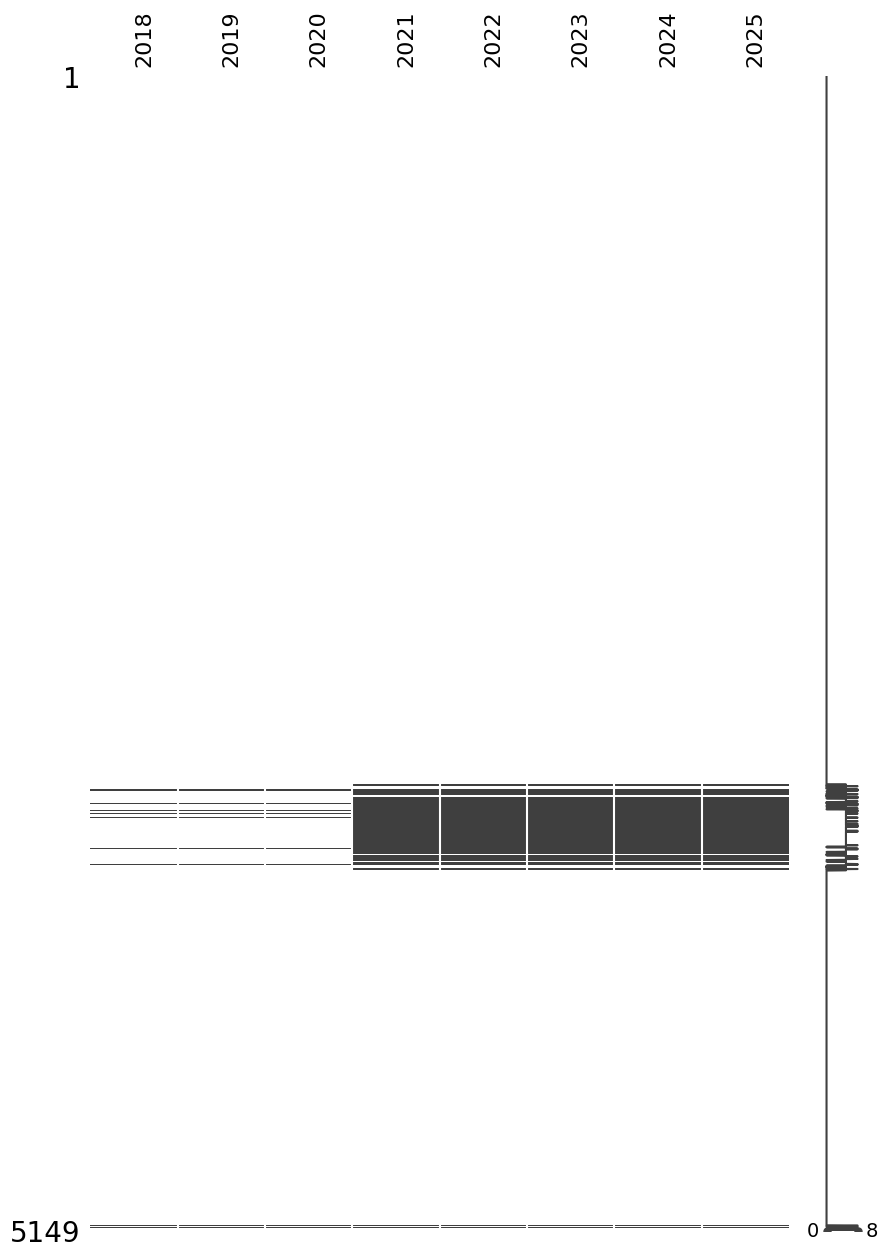

In [62]:
cons = pd.read_csv("../data/raw/consumer.csv")
print("Shape", cons.shape)
# msno.matrix(cons, figsize=(20, 10))
# plt.xticks(rotation=90)
# plt.show()

# cons_2018_22_cols = [col for col in cons.columns if ('20' not in col or ('20' in col and '-' not in col and int(col)>2017))]
cons_2018_22_cols = [col for col in cons.columns if '20' in col and '-' not in col and int(col)>2017]
msno.matrix(cons[cons_2018_22_cols], figsize=(10, 15))
plt.xticks(rotation=90)
plt.show()

In [63]:
print("Number of missing values for 2019 out of 5149 rows ",cons["2019"].isna().sum(), "present values : " ,cons.shape[0] - cons["2019"].isna().sum())
print("Number of missing values for 2020 out of 5149 rows ",cons["2020"].isna().sum(), "present values : " ,cons.shape[0] - cons["2020"].isna().sum())
print("Number of missing values for 2021 out of 5149 rows ",cons["2021"].isna().sum(), "present values : " ,cons.shape[0] - cons["2021"].isna().sum())
print("Number of missing values for 2022 out of 5149  rows ",cons["2022"].isna().sum(), "present values : " ,cons.shape[0] - cons["2022"].isna().sum())
print("Number of missing values for 2023 out of 5149 rows ",cons["2023"].isna().sum(), "present values : " ,cons.shape[0] - cons["2023"].isna().sum())
print("Number of missing values for 2024 out of 5149  rows ",cons["2024"].isna().sum(), "present values : " ,cons.shape[0] - cons["2024"].isna().sum())
print("Number of missing values for 2025 out of 5149 rows ",cons["2025"].isna().sum(), "present values : " ,cons.shape[0] - cons["2025"].isna().sum())

Number of missing values for 2019 out of 5149 rows  5098 present values :  51
Number of missing values for 2020 out of 5149 rows  5098 present values :  51
Number of missing values for 2021 out of 5149 rows  4798 present values :  351
Number of missing values for 2022 out of 5149  rows  4798 present values :  351
Number of missing values for 2023 out of 5149 rows  4798 present values :  351
Number of missing values for 2024 out of 5149  rows  4798 present values :  351
Number of missing values for 2025 out of 5149 rows  4798 present values :  351


# Reflection point
We have observed 3 complete datasets: household, labour and consumer goods. 
- Household: rejected immediately because doesn't have any information ater 2021 (full scale invasion in 2022)
- Consumer goods indicators: has rather consistent pattern for each year 2018-2025 but with only 351 values in average
- Labour indicators: has lot's of missign values in 2022-2023 but has enough of inforamtion in 2021 and 2024-2025 to compare the period before and after full scale invasion in Ukraine. 

Decision: keeping Labour indicators.
We could use ML techiniques studied later to predict and fill in the missing values.

In [73]:
# 1. Define your year columns list
year_cols = ["2018","2019", "2020", "2021", "2022", "2023", "2024", "2025"]

# 2. Calculate how many years of data each row actually has
valid_counts = data[year_cols].notna().sum(axis=1)

# Optional: Print a quick distribution to see how complete your rows are
print(valid_counts.value_counts())

# 3. Filter to keep only rows that have data for at least X years 
# (For example, if you want rows present in ALL 7 years, set threshold to 7)
# (If you want rows present in at least 5 out of 7 years, set threshold to 5)
threshold = 3
filtered_data = data[valid_counts >= threshold].copy()

print(f"Original shape: {data.shape}")
print(f"Filtered shape: {filtered_data.shape}")
display(filtered_data.head())
annual_cols = [col for col in filtered_data.columns if ('20' not in col )or('-'  not in col and int(col)>2017)]
print(filtered_data[annual_cols].columns)

0    17888
3     4369
2     1210
1      479
4       43
7       26
6       25
5       18
8        1
Name: count, dtype: int64
Original shape: (24059, 468)
Filtered shape: (4482, 468)


,Indicator,Region,Availability of seasonal adjustment,Economic activity type,Breakdown category,Breakdown,Frequency,Indicator update date,Indicator next update date,Unit of measure,...,2026-Q1,2026-M01,2026-M02,2026-M03,2026-Q2,2026-M04,2026-M05,2026-M06,2026-M07,2026-M08
6,Average monthly salary (nominal) of a full-tim...,Ukraine,Not applicable,Air transport,Sex,Total,Annual,NaN,NaN,UAH,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
12,Average monthly salary (nominal) of a full-tim...,Ukraine,Not applicable,Land transport and transport via pipelines,Sex,Total,Annual,NaN,NaN,UAH,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
32,Average monthly salary (nominal) of a full-tim...,Ukraine,Not applicable,Water transport,Sex,Total,Annual,NaN,NaN,UAH,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
47,Average monthly salary (nominal) of a full-tim...,Ukraine,Not applicable,Agriculture and related services,Sex,Total,Annual,NaN,NaN,UAH,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
53,Average monthly salary (nominal) of a full-tim...,Ukraine,Not applicable,Mining of coal and lignite,Sex,Total,Annual,NaN,NaN,UAH,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Index(['Indicator', 'Region', 'Availability of seasonal adjustment',
       'Economic activity type', 'Breakdown category', 'Breakdown',
       'Frequency', 'Indicator update date', 'Indicator next update date',
       'Unit of measure', 'Scaling', 'Decimals displayed', 'Observation flag',
       'Dataset notes', 'Timeseries notes', 'Observation notes', '2018',
       '2019', '2020', '2021', '2022', '2023', '2024', '2025'],
      dtype='object')


Index(['Indicator', 'Region', 'Availability of seasonal adjustment',
       'Economic activity type', 'Breakdown category', 'Breakdown',
       'Frequency', 'Indicator update date', 'Indicator next update date',
       'Unit of measure', 'Scaling', 'Decimals displayed', 'Observation flag',
       'Dataset notes', 'Timeseries notes', 'Observation notes', '2018',
       '2019', '2020', '2021', '2022', '2023', '2024', '2025'],
      dtype='object')


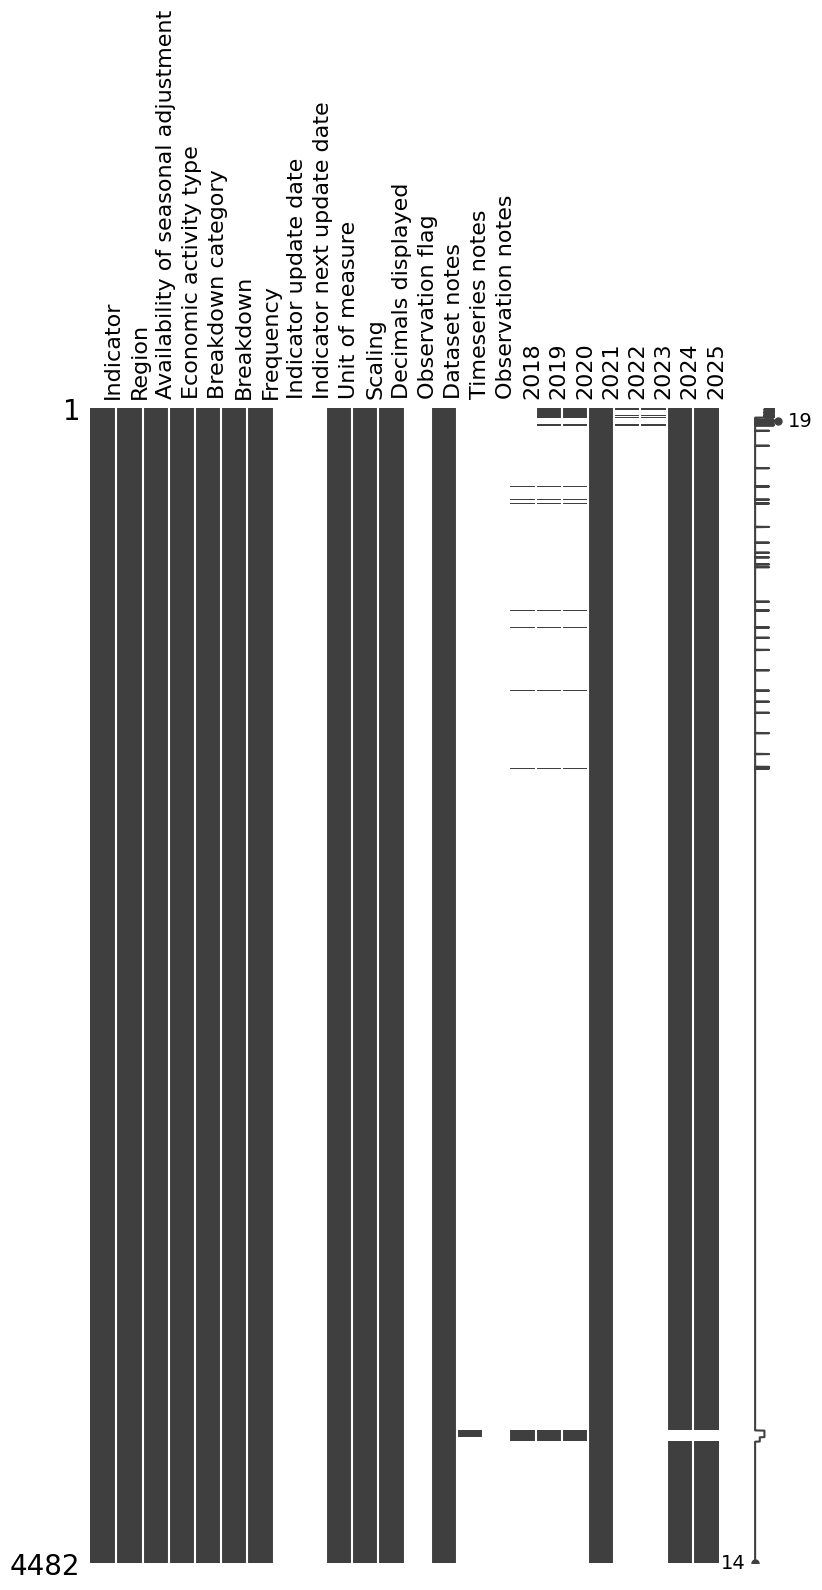

In [77]:
print(filtered_data[annual_cols].columns)
msno.matrix(filtered_data[annual_cols], figsize=(9, 15))
plt.xticks(rotation=90)
plt.show()

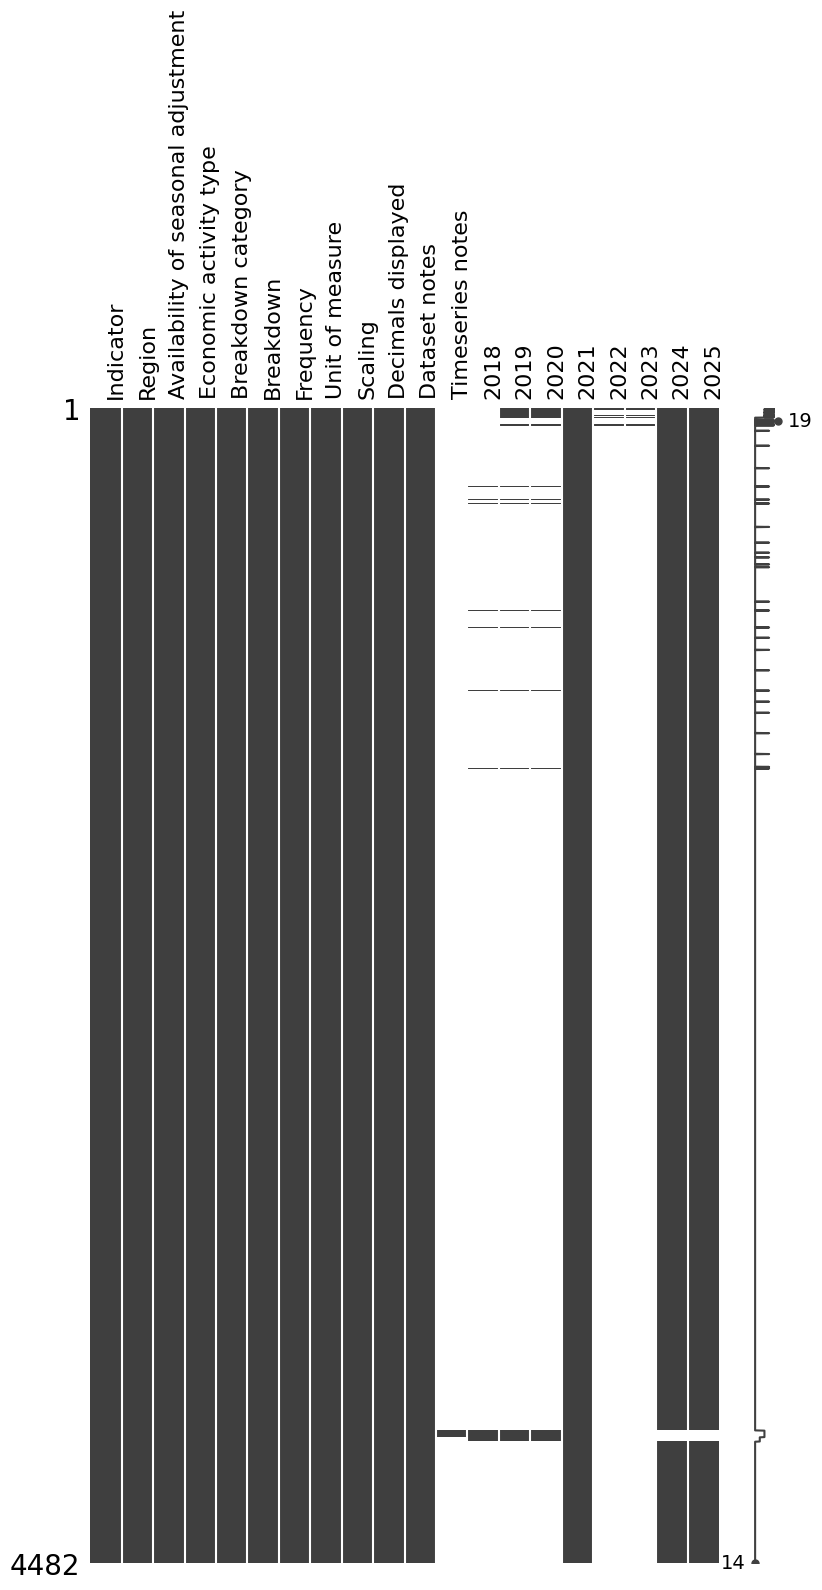

,2018,2019,2020,2021,2022,2023,2024,2025
count,69.000000,113.000000,113.000000,4482.000000,27.000000,27.000000,4439.000000,4439.000000
mean,3095.779710,6686.019469,7234.400000,9478.024208,15080.629630,18203.185185,10543.102275,11799.965758
std,3963.752412,5858.951365,6175.485407,17263.850595,5474.404198,6923.878760,15528.699823,16788.244230
min,61.600000,63.900000,63.500000,1.000000,8592.000000,10990.000000,1.000000,1.000000
25%,109.500000,108.700000,108.500000,177.000000,11783.000000,13760.000000,124.000000,114.000000
50%,112.700000,8396.000000,9384.000000,4427.500000,13738.000000,15509.000000,3331.000000,3318.000000
75%,7365.000000,10480.000000,11288.000000,12069.750000,15139.500000,19994.500000,16887.000000,19843.500000
max,13542.000000,27300.000000,21685.000000,267381.000000,30829.000000,37946.000000,237295.000000,239346.000000


In [ ]:
labour_2018_22 = filtered_data['Indicator', 'Region', 'Availability of seasonal adjustment',
       'Economic activity type', 'Breakdown category', 'Breakdown',
       'Frequency', 'Indicator update date', 'Indicator next update date',
       'Unit of measure', 
       'Scaling', 
       'Decimals displayed', 'Observation flag',
       'Dataset notes', 
       'Timeseries notes', 'Observation notes', 
       '2018',
       '2019', '2020', '2021', '2022', '2023', '2024', '2025']
msno.matrix(labour_2018_22, figsize=(9, 15))
plt.xticks(rotation=90)
plt.show()
# labour_2018_22.describe()

In [102]:
# labour_2018_22 = filtered_data['Indicator', 'Region', 'Availability of seasonal adjustment',
#        'Economic activity type', 'Breakdown category', 'Breakdown',
#        'Frequency', 'Indicator update date', 'Indicator next update date',
#        'Unit of measure', 
#        'Scaling', 
#        'Decimals displayed', 
#        'Dataset notes', 
#        'Timeseries notes', 
#        '2018',
#        '2019', '2020', '2021', '2022', '2023', '2024', '2025']
display(labour_2018_22['Scaling'].value_counts())
display(labour_2018_22['Decimals displayed'].value_counts())
display(labour_2018_22['Dataset notes'].value_counts())
display(labour_2018_22['Timeseries notes'].value_counts())
display(labour_2018_22['Breakdown'].value_counts())
display(labour_2018_22['Breakdown category'].value_counts())
display(labour_2018_22['Economic activity type'].value_counts())
display(labour_2018_22['Availability of seasonal adjustment'].value_counts())
display(labour_2018_22['Unit of measure'].value_counts())

Scaling
Units    4482
Name: count, dtype: int64

Decimals displayed
Zero    4439
One       43
Name: count, dtype: int64

Dataset notes
1. Data are compiled according to the results from the state statistical observation “Survey of enterprises on issues concerning labor statistics” which covers legal persons and detached units of legal persons with 10 and more employees. 2. Data for 2014-2021 / Data for 2014-2021, January, February 2022 exclude the temporarily occupied territories of the Autonomous Republic of Crimea, the city of Sevastopol and a part of temporarily occupied territories in the Donetsk and Luhansk regions. Beginning from 2022 / Beginning from March 2022 / Beginning from the 1st quarter of 2022 data exclude the territories which are temporarily occupied by the russian federation and part of territories where the military actions are/were conducted.    4482
Name: count, dtype: int64

Timeseries notes
1. Real wages characterize the purchasing power of nominal wages under the influence of changes in consumer prices for goods and services and the level of taxes and mandatory payments. 2. The real wage index is calculated by dividing the index of accrued nominal wages (excluding personal income tax and military service) by the consumer price index. 3. Information on the real wage index is calculated for Ukraine as a whole and by regions.    26
Name: count, dtype: int64

Breakdown
Total             3182
Female             805
Male               452
Not applicable      43
Name: count, dtype: int64

Breakdown category
Sex               4439
Not applicable      43
Name: count, dtype: int64

Economic activity type
Human health and social work activities                                                               248
Education                                                                                             248
Public administration and defence; compulsory social security                                         247
Industry                                                                                              239
Arts, entertainment and recreation                                                                    237
Manufacturing                                                                                         236
Transporting and storage                                                                              235
Financial and insurance activities                                                                    233
Electricity, gas, steam and air conditioning supply                                                   233
Professional, scientifi

Availability of seasonal adjustment
Not applicable    4482
Name: count, dtype: int64

Unit of measure
Person     2629
UAH        1428
Unit        382
Percent      43
Name: count, dtype: int64

In [108]:
labour_2018_22_cleaned = labour_2018_22[[ 'Indicator', 'Region', 
       'Economic activity type', 'Breakdown',
       'Unit of measure', 
       '2018',
       '2019', '2020', '2021', '2022', '2023', '2024', '2025']]
display(labour_2018_22_cleaned)
print(labour_2018_22_cleaned.shape)

,Indicator,Region,Economic activity type,Breakdown,Unit of measure,2018,2019,2020,2021,2022,2023,2024,2025
6,Average monthly salary (nominal) of a full-tim...,Ukraine,Air transport,Total,UAH,NaN,27300.0,21685.0,28506.0,24963.0,31391.0,43416.0,57471.0
12,Average monthly salary (nominal) of a full-tim...,Ukraine,Land transport and transport via pipelines,Total,UAH,NaN,10705.0,11288.0,13121.0,13111.0,15452.0,19323.0,23057.0
32,Average monthly salary (nominal) of a full-tim...,Ukraine,Water transport,Total,UAH,NaN,13057.0,12807.0,14473.0,14773.0,21858.0,25768.0,25044.0
47,Average monthly salary (nominal) of a full-tim...,Ukraine,Agriculture and related services,Total,UAH,NaN,8738.0,9734.0,11733.0,12243.0,14184.0,17710.0,24034.0
53,Average monthly salary (nominal) of a full-tim...,Ukraine,Mining of coal and lignite,Total,UAH,NaN,14831.0,15701.0,17883.0,NaN,NaN,29723.0,35090.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
21605,Average number of regular workers,Kyiv,Real estate activities,Total,Person,NaN,NaN,NaN,21696.0,NaN,NaN,18365.0,17592.0
21607,Average number of regular workers,Kyiv,Public administration and defence; compulsory ...,Total,Person,NaN,NaN,NaN,59470.0,NaN,NaN,59509.0,57733.0
21611,Average number of regular workers,Kyiv,Industry,Total,Person,NaN,NaN,NaN,119467.0,NaN,NaN,121282.0,137089.0
21624,Average number of regular workers,Kyiv,Wholesale and retail trade; repair of motor ve...,Total,Person,NaN,NaN,NaN,250026.0,NaN,NaN,222696.0,225563.0


(4482, 13)


# Preprocessing conclusion
We had columns with no values such as  `Indicator update date`, `Indicator next update date`, `Observartion flag` or columns that are repeated such as `Scaling`, `Timeseries notes`, `Dataset notes`. `Availability of seasonal adjustment`, `Frequency`(always annual), `breakdown category` and `decimals displayed` are not really useful for us, so we drop them too.
We kept only [ 'Indicator', 'Region', 
       'Economic activity type', 'Breakdown',
       'Unit of measure', 
       '2018',
       '2019', '2020', '2021', '2022', '2023', '2024', '2025']
       
The dataset contains now 4482 rows and 13 columns.

We can explore it to analyze what data we have.



## distribution **GOOD**

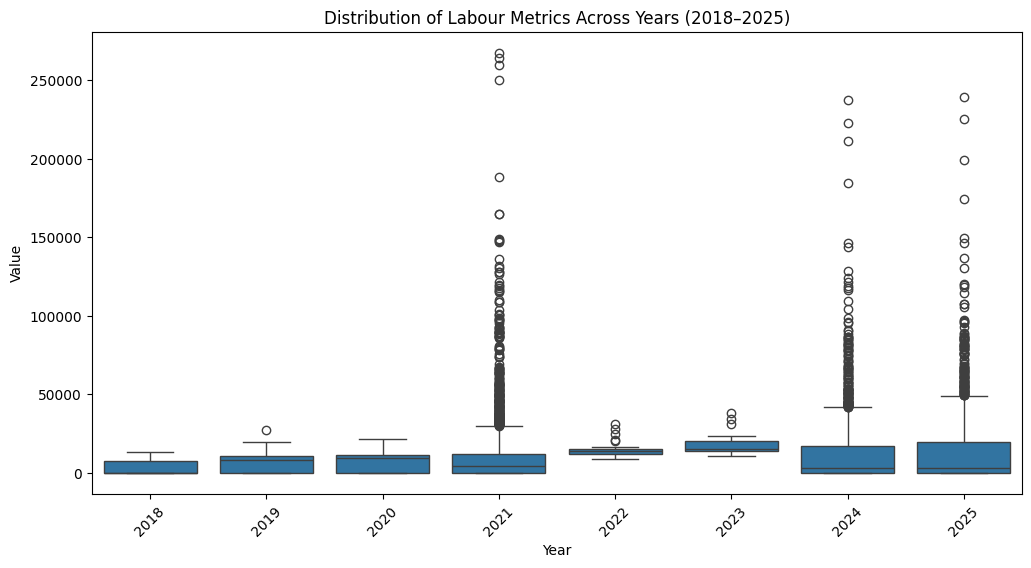

In [109]:
# Reshape the year columns into long format temporarily just for plotting
df_melted = labour_2018_22_cleaned.melt(
    id_vars=['Indicator', 'Region', 'Economic activity type', 'Breakdown', 'Unit of measure'],
    value_vars=['2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025'],
    var_name='Year', value_name='Value'
)

# Convert Value to numeric (just in case)
df_melted['Value'] = pd.to_numeric(df_melted['Value'], errors='coerce')

plt.figure(figsize=(12, 6))
sns.boxplot(data=df_melted, x='Year', y='Value')
plt.title('Distribution of Labour Metrics Across Years (2018–2025)')
plt.xticks(rotation=45)
plt.show()

## by regions /by indicator (not good mix of values)

In [140]:
# Filter for one specific indicator (replace with an actual indicator name from your dataset)
sample_indicator = labour_2018_22_cleaned['Indicator'].unique()[4] 

subset = labour_2018_22_cleaned[labour_2018_22_cleaned['Indicator'] == sample_indicator]

# # Plot top 15 regions for 2023
# plt.figure(figsize=(12, 6))
# subset.sort_values(by='2024', ascending=False).head(15).plot(
#     x='Region', y='2024', kind='bar', color='skyblue'
# )
# plt.title(f'Top 15 Regions for: {sample_indicator} (2024)')
# plt.ylabel('Value')
# plt.xticks(rotation=45, ha='right')
# plt.show()

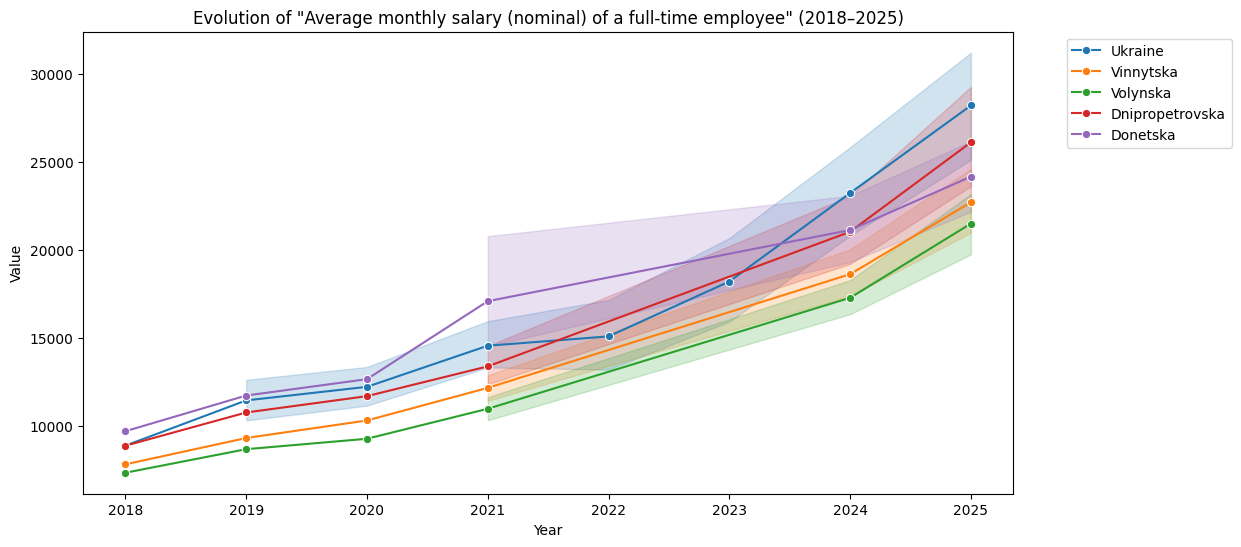

In [122]:
# Filter for a specific indicator and a few selected regions
selected_regions = subset['Region'].unique()[:5] # Take the first 5 regions as an example
time_subset = subset[subset['Region'].isin(selected_regions)]

# Melt to get Year as a column for line plotting
time_melted = time_subset.melt(
    id_vars=['Region'],
    value_vars=['2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025'],
    var_name='Year', value_name='Value'
)
time_melted['Value'] = pd.to_numeric(time_melted['Value'], errors='coerce')

plt.figure(figsize=(12, 6))
sns.lineplot(data=time_melted, x='Year', y='Value', hue='Region', marker='o')
plt.title(f'Evolution of "{sample_indicator}" (2018–2025)')
plt.ylabel('Value')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

['Average monthly salary (nominal) of a full-time employee'
 'Number of registered collective agreements'
 'Regіstered number of regular employees who are on leave due to pregnanсy and сhіldbіrth at the end of the reportіng perіod'
 'Regіstered number of regular employees who are on parental leave at the end of the reportіng perіod'
 'Regіstered number of regular employees reсruіted on a part-tіme workіng day/week basіs at the end of the reportіng perіod'
 'Regіstered number of regular employees at the end of the reportіng perіod'
 'Number of persons сovered by сolleсtіve agreements'
 'Indices for real wage percent of the previous period (year, month, etc.)'
 'Ratio of average wages for men and women'
 'Average number of regular workers']


/var/folders/d3/_3prq75j4zs7ww42zcnxc6bw0000gn/T/ipykernel_29157/357570093.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=activity_summary, x='2021', y='Indicator', palette='viridis')


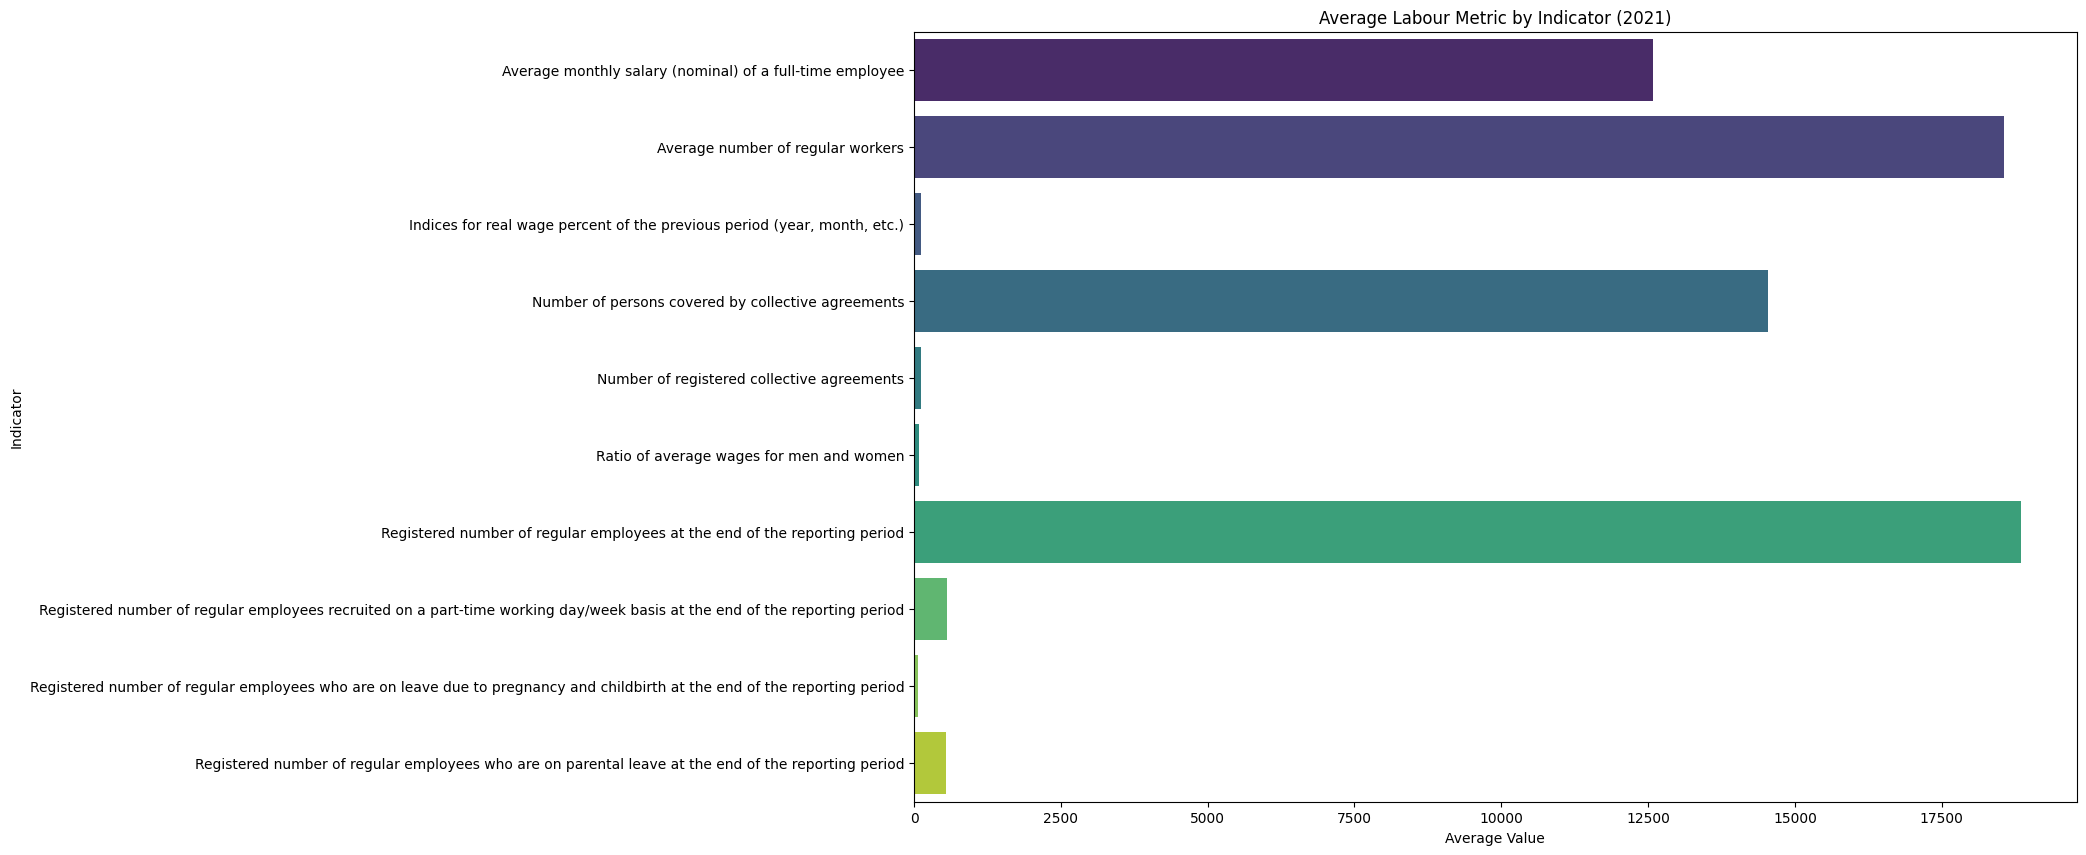

In [142]:
# See what unique economic activity types you have
print(labour_2018_22_cleaned['Indicator'].unique())

# Group by economic activity and find the mean value for 2023
activity_summary = labour_2018_22_cleaned.groupby('Indicator')['2021'].mean().reset_index()

plt.figure(figsize=(15, 10))
sns.barplot(data=activity_summary, x='2021', y='Indicator', palette='viridis')
plt.title('Average Labour Metric by Indicator (2021)')
plt.xlabel('Average Value')
plt.show()

## graph with linear functions grouped by activity type **GOOD**

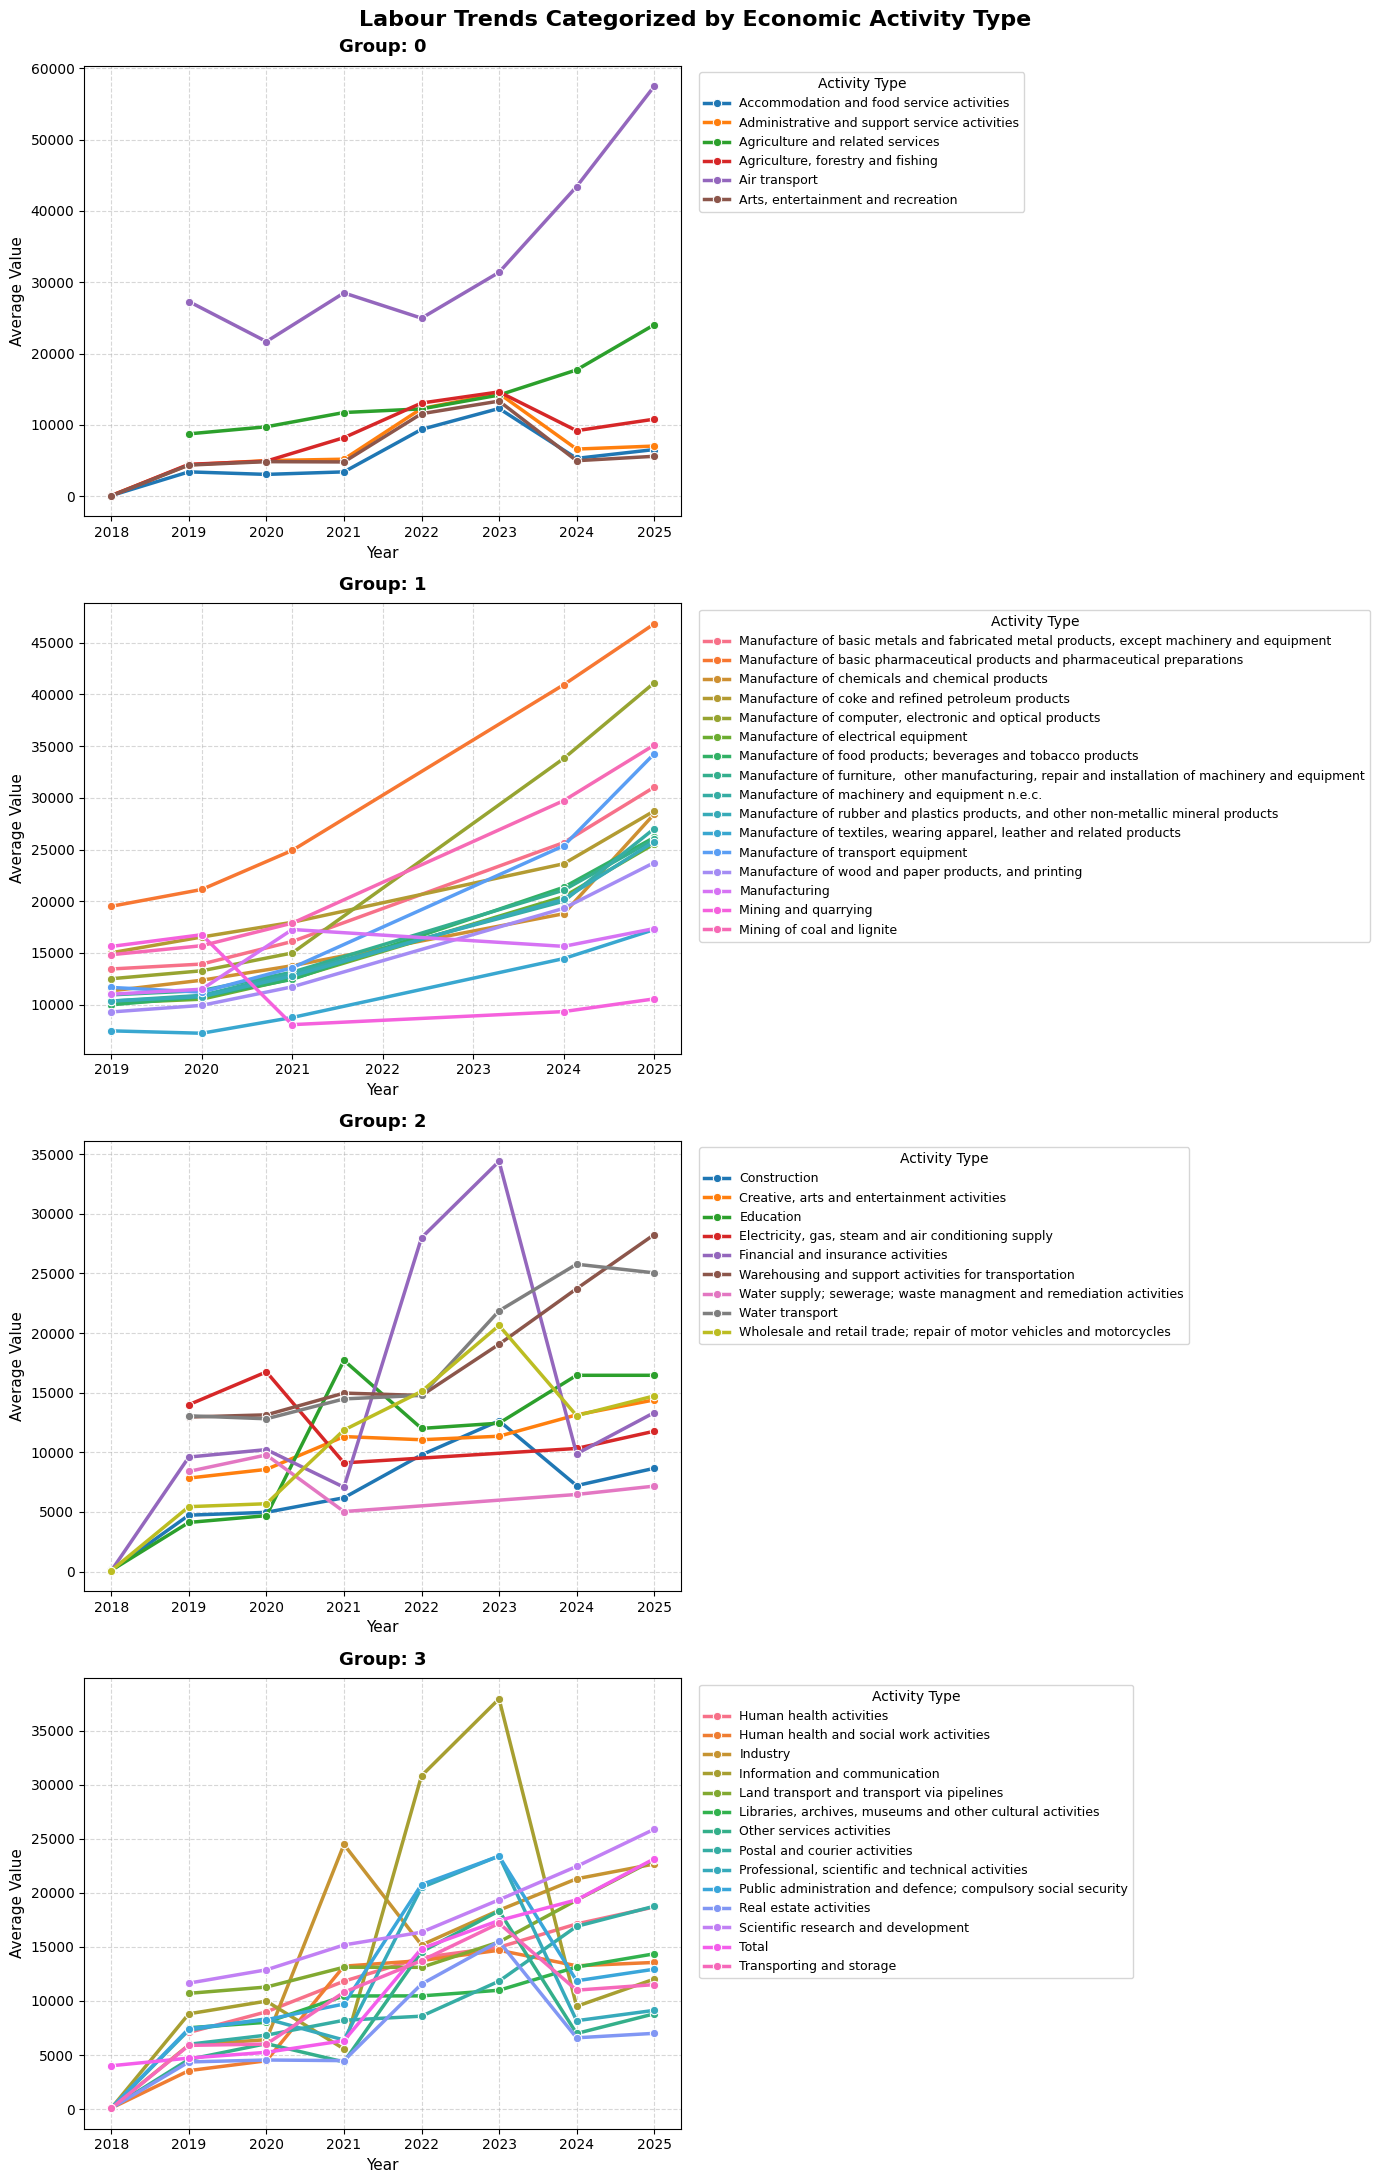

In [139]:
# 1. Prepare your trend data
years = ['2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025']
available_years = [y for y in years if y in labour_2018_22_cleaned.columns]

summary_list = []
for year in available_years:
    temp_df = labour_2018_22_cleaned.copy()
    temp_df[year] = pd.to_numeric(temp_df[year], errors='coerce')
    grouped = temp_df.groupby('Economic activity type')[year].mean().reset_index()
    grouped['Year'] = year
    grouped.rename(columns={year: 'Average Value'}, inplace=True)
    summary_list.append(grouped)

trend_df = pd.concat(summary_list, ignore_index=True)

# 2. Define category function for starting letters
def categorize_activity(name):
    if not isinstance(name, str):
        return 'Rest'
    name_lower = name.lower()
    if name_lower.startswith('w') or name_lower.startswith('c') or name_lower.startswith('e') or name_lower.startswith('f'):
        return 'Starts with W'
    elif name_lower.startswith('m'):
        return 'Starts with M'
    elif name_lower.startswith('a'):
        return 'Starts with A'
    else:
        return 'Rest'

trend_df['Category_Group'] = trend_df['Economic activity type'].apply(categorize_activity)

# 3. Set up a vertical stack of 4 subplots (row by row: 4 rows, 1 column)
groups = ['Starts with A', 'Starts with M', 'Starts with W', 'Rest']
fig, axes = plt.subplots(nrows=4, ncols=1, figsize=(14, 22), sharex=False)

for i, group_name in enumerate(groups):
    ax = axes[i]
    sub_data = trend_df[trend_df['Category_Group'] == group_name]
    
    if not sub_data.empty:
        n_items = sub_data['Economic activity type'].nunique()
        palette = sns.color_palette("tab10", n_items) if n_items <= 10 else sns.color_palette("husl", n_items)
        
        sns.lineplot(
            data=sub_data,
            x='Year',
            y='Average Value',
            hue='Economic activity type',
            marker='o',
            linewidth=2.5,
            palette=palette,
            ax=ax
        )
        
    ax.set_title(f'Group: {i}', fontsize=13, fontweight='bold', pad=10)
    ax.set_xlabel('Year', fontsize=11)
    ax.set_ylabel('Average Value', fontsize=11)
    ax.grid(True, linestyle='--', alpha=0.5)
    
    # Place legend neatly outside to the right of each subplot
    ax.legend(title='Activity Type', fontsize=9, title_fontsize=10, bbox_to_anchor=(1.02, 1), loc='upper left')

plt.suptitle('Labour Trends Categorized by Economic Activity Type', fontsize=16, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()

## graph general (not good bc the mix of units)

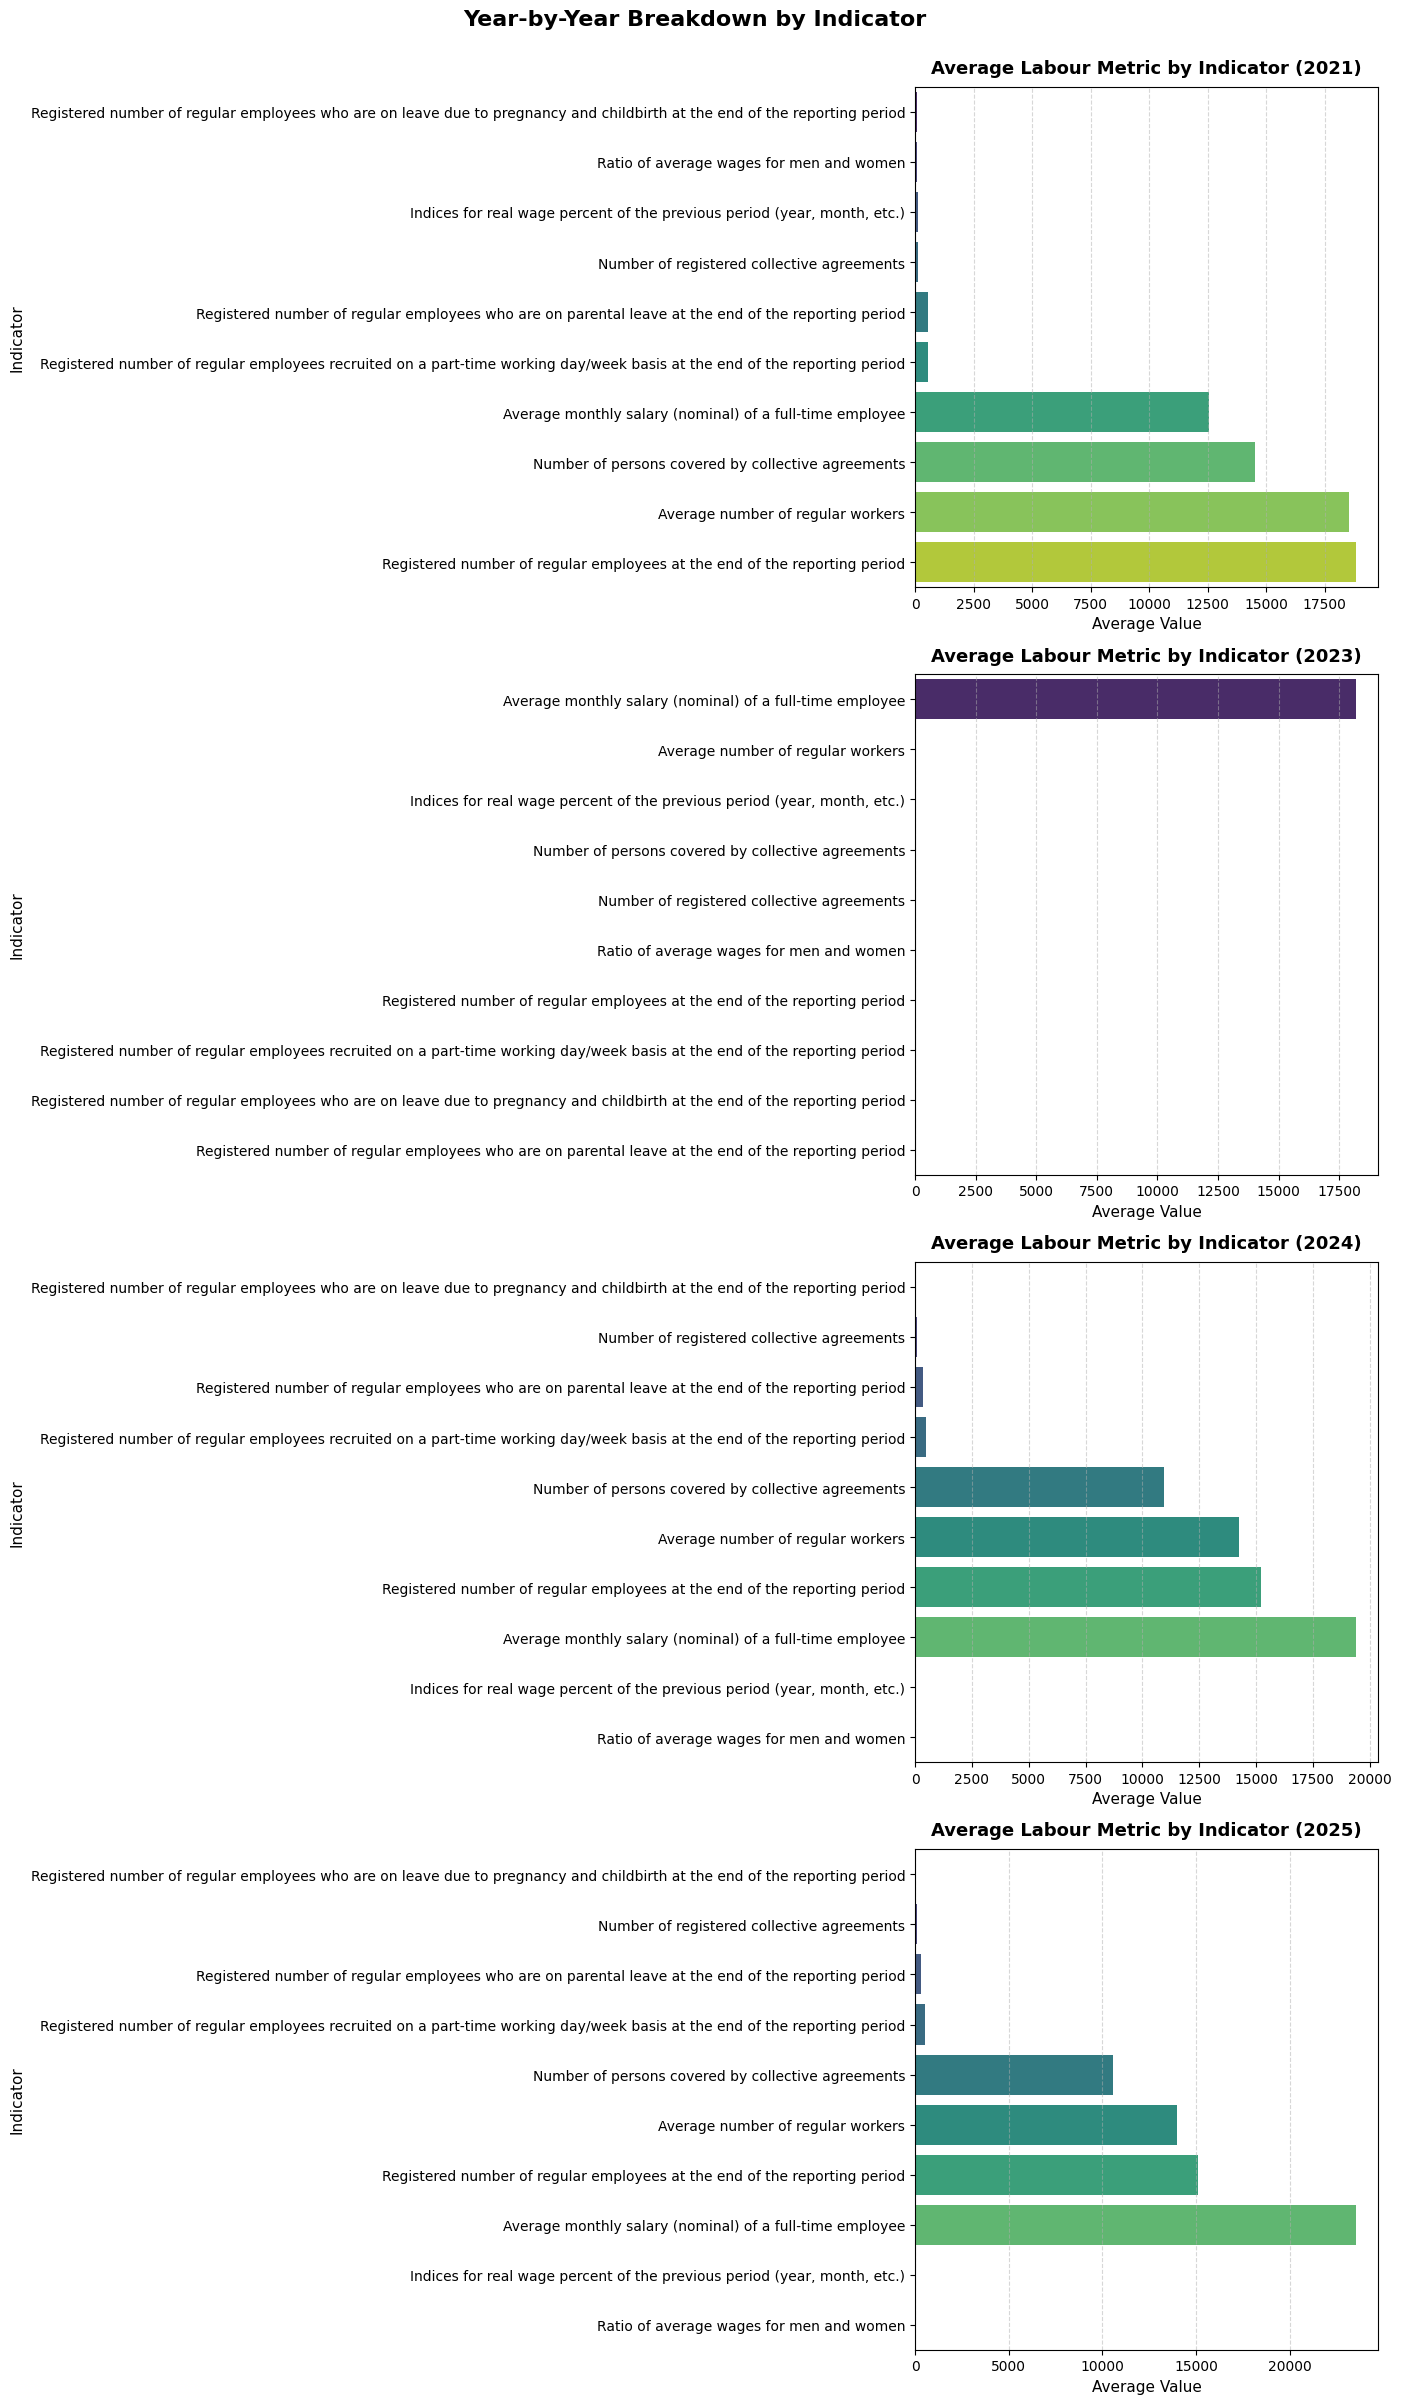

In [145]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Define available years
# years = ['2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025']
years = ['2021','2023', '2024', '2025']
available_years = [y for y in years if y in labour_2018_22_cleaned.columns]

# 2. Set up a vertical stack of subplots (one row per year)
fig, axes = plt.subplots(nrows=len(available_years), ncols=1, figsize=(14, len(available_years) * 6))

# If there's only 1 year, convert axes to a list so the loop works
if len(available_years) == 1:
    axes = [axes]

for i, year in enumerate(available_years):
    ax = axes[i]
    
    # Ensure the year column is numeric
    temp_df = labour_2018_22_cleaned.copy()
    temp_df[year] = pd.to_numeric(temp_df[year], errors='coerce')
    
    # Group by Indicator and find the mean for this year
    indicator_summary = temp_df.groupby('Indicator')[year].mean().reset_index()
    
    # Sort values so the bars appear neatly from smallest to largest
    indicator_summary = indicator_summary.sort_values(by=year, ascending=True)
    
    # Plot horizontal bar chart (perfect for long indicator names)
    sns.barplot(
        data=indicator_summary, 
        x=year, 
        y='Indicator', 
        ax=ax, 
        palette='viridis',
        hue='Indicator',
        legend=False
    )
    
    ax.set_title(f'Average Labour Metric by Indicator ({year})', fontsize=13, fontweight='bold', pad=10)
    ax.set_xlabel('Average Value', fontsize=11)
    ax.set_ylabel('Indicator', fontsize=11)
    ax.grid(True, linestyle='--', alpha=0.5, axis='x')

plt.suptitle('Year-by-Year Breakdown by Indicator', fontsize=16, fontweight='bold', y=1.0)
plt.tight_layout()
plt.show()

## one bar graph (with the choice of unit)

Units available: ['UAH' 'Unit' 'Person' 'Percent']


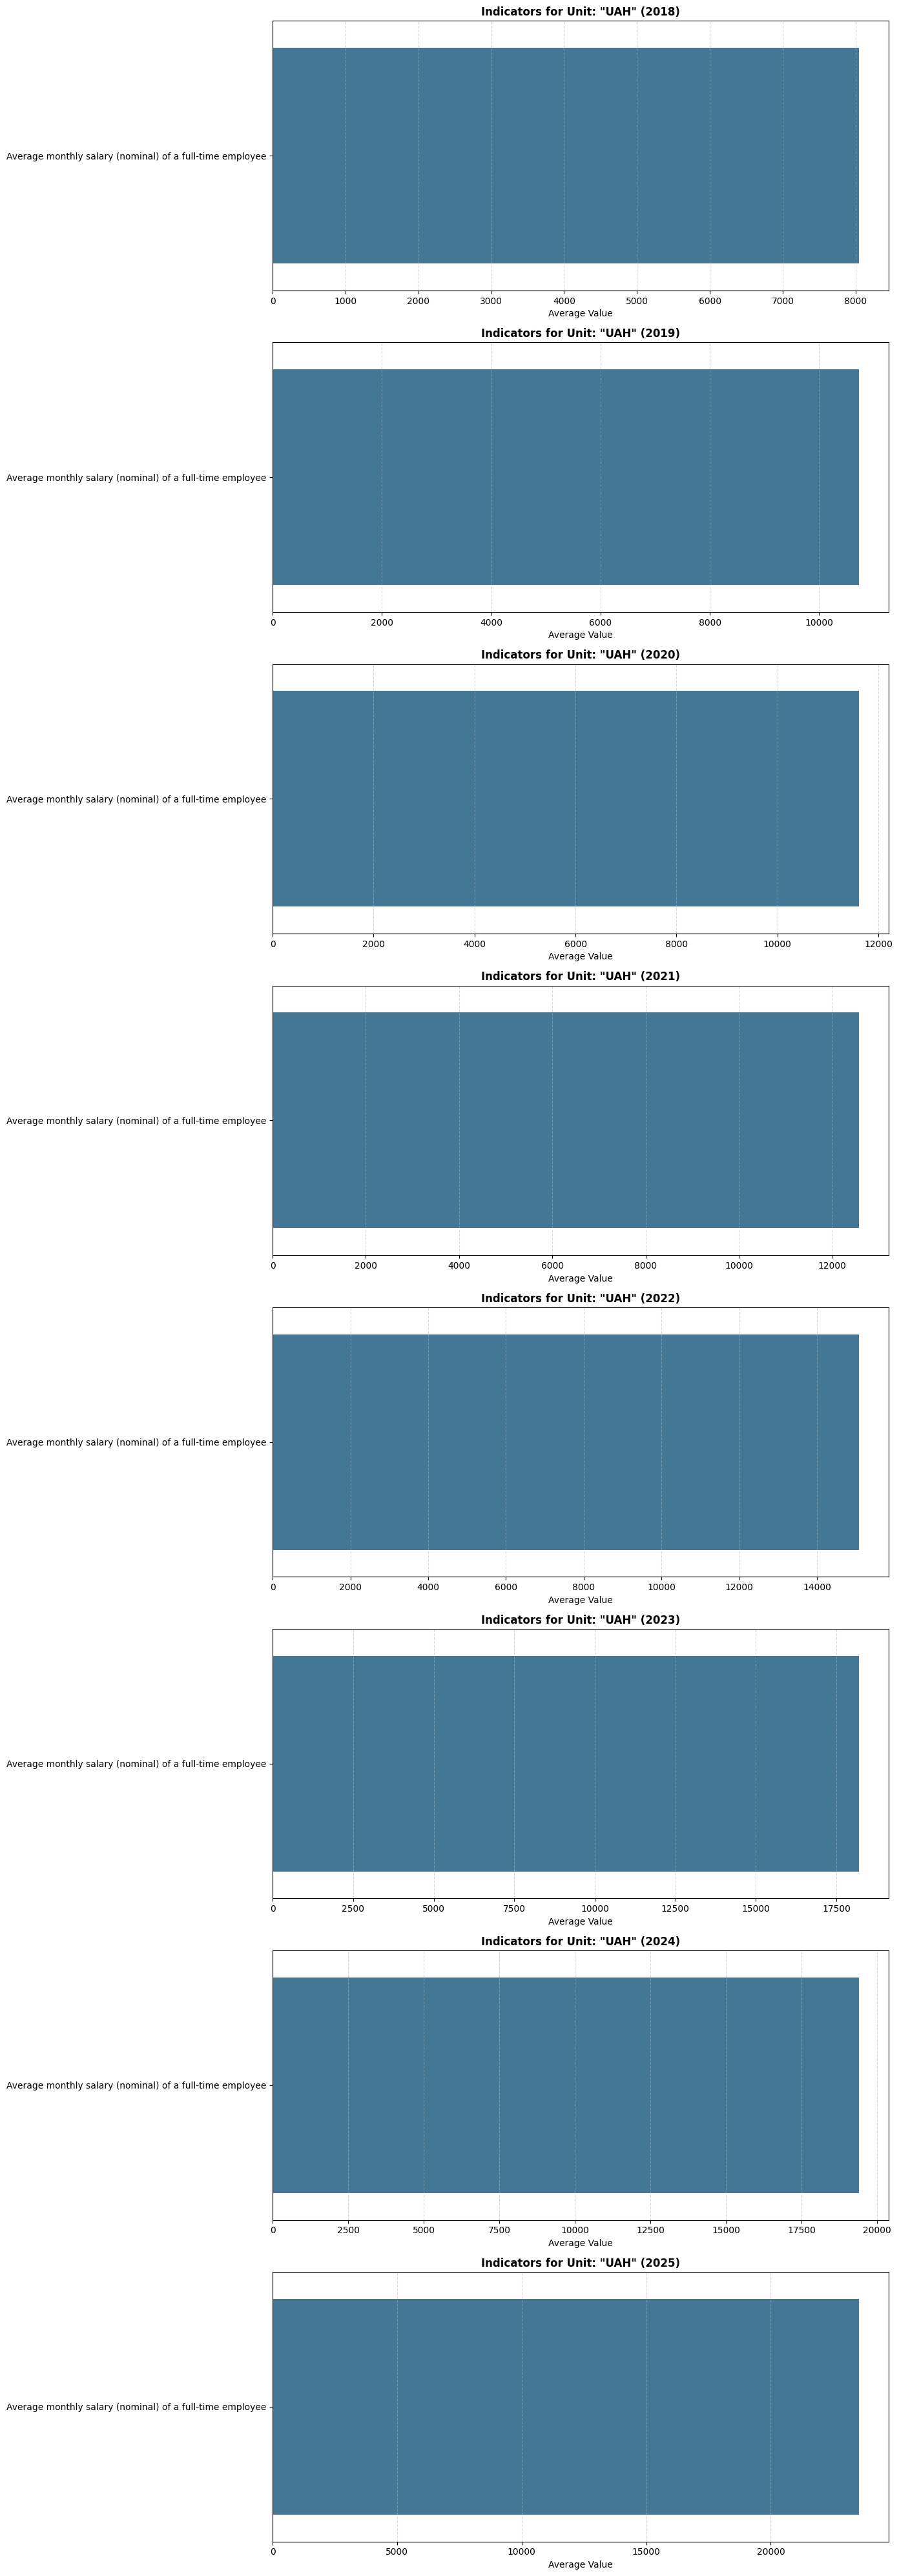

In [151]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Check what unique units of measure you have
print("Units available:", labour_2018_22_cleaned['Unit of measure'].unique())

# 2. Pick a specific unit to plot (e.g., percentages or rates)
# Replace 'Percentage' with whatever exact string appears in your 'Unit of measure' column
target_unit = labour_2018_22_cleaned['Unit of measure'].unique()[0] 
subset_unit = labour_2018_22_cleaned[labour_2018_22_cleaned['Unit of measure'] == target_unit]

# 3. Plot year-by-year subplots for this specific unit
years = ['2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025']
available_years = [y for y in years if y in subset_unit.columns]

fig, axes = plt.subplots(nrows=len(available_years), ncols=1, figsize=(14, len(available_years) * 5))
if len(available_years) == 1:
    axes = [axes]

for i, year in enumerate(available_years):
    ax = axes[i]
    temp_df = subset_unit.copy()
    temp_df[year] = pd.to_numeric(temp_df[year], errors='coerce')
    
    indicator_summary = temp_df.groupby('Indicator')[year].mean().reset_index().sort_values(by=year, ascending=True)
    
    sns.barplot(data=indicator_summary, x=year, y='Indicator', ax=ax, palette='mako', hue='Indicator', legend=False)
    ax.set_title(f'Indicators for Unit: "{target_unit}" ({year})', fontsize=12, fontweight='bold')
    ax.set_xlabel('Average Value', fontsize=10)
    ax.set_ylabel('')
    ax.grid(True, linestyle='--', alpha=0.5, axis='x')

plt.tight_layout()
plt.show()

## graphs by units (distribution)

Found 4 unique units of measure: ['UAH', 'Unit', 'Person', 'Percent']


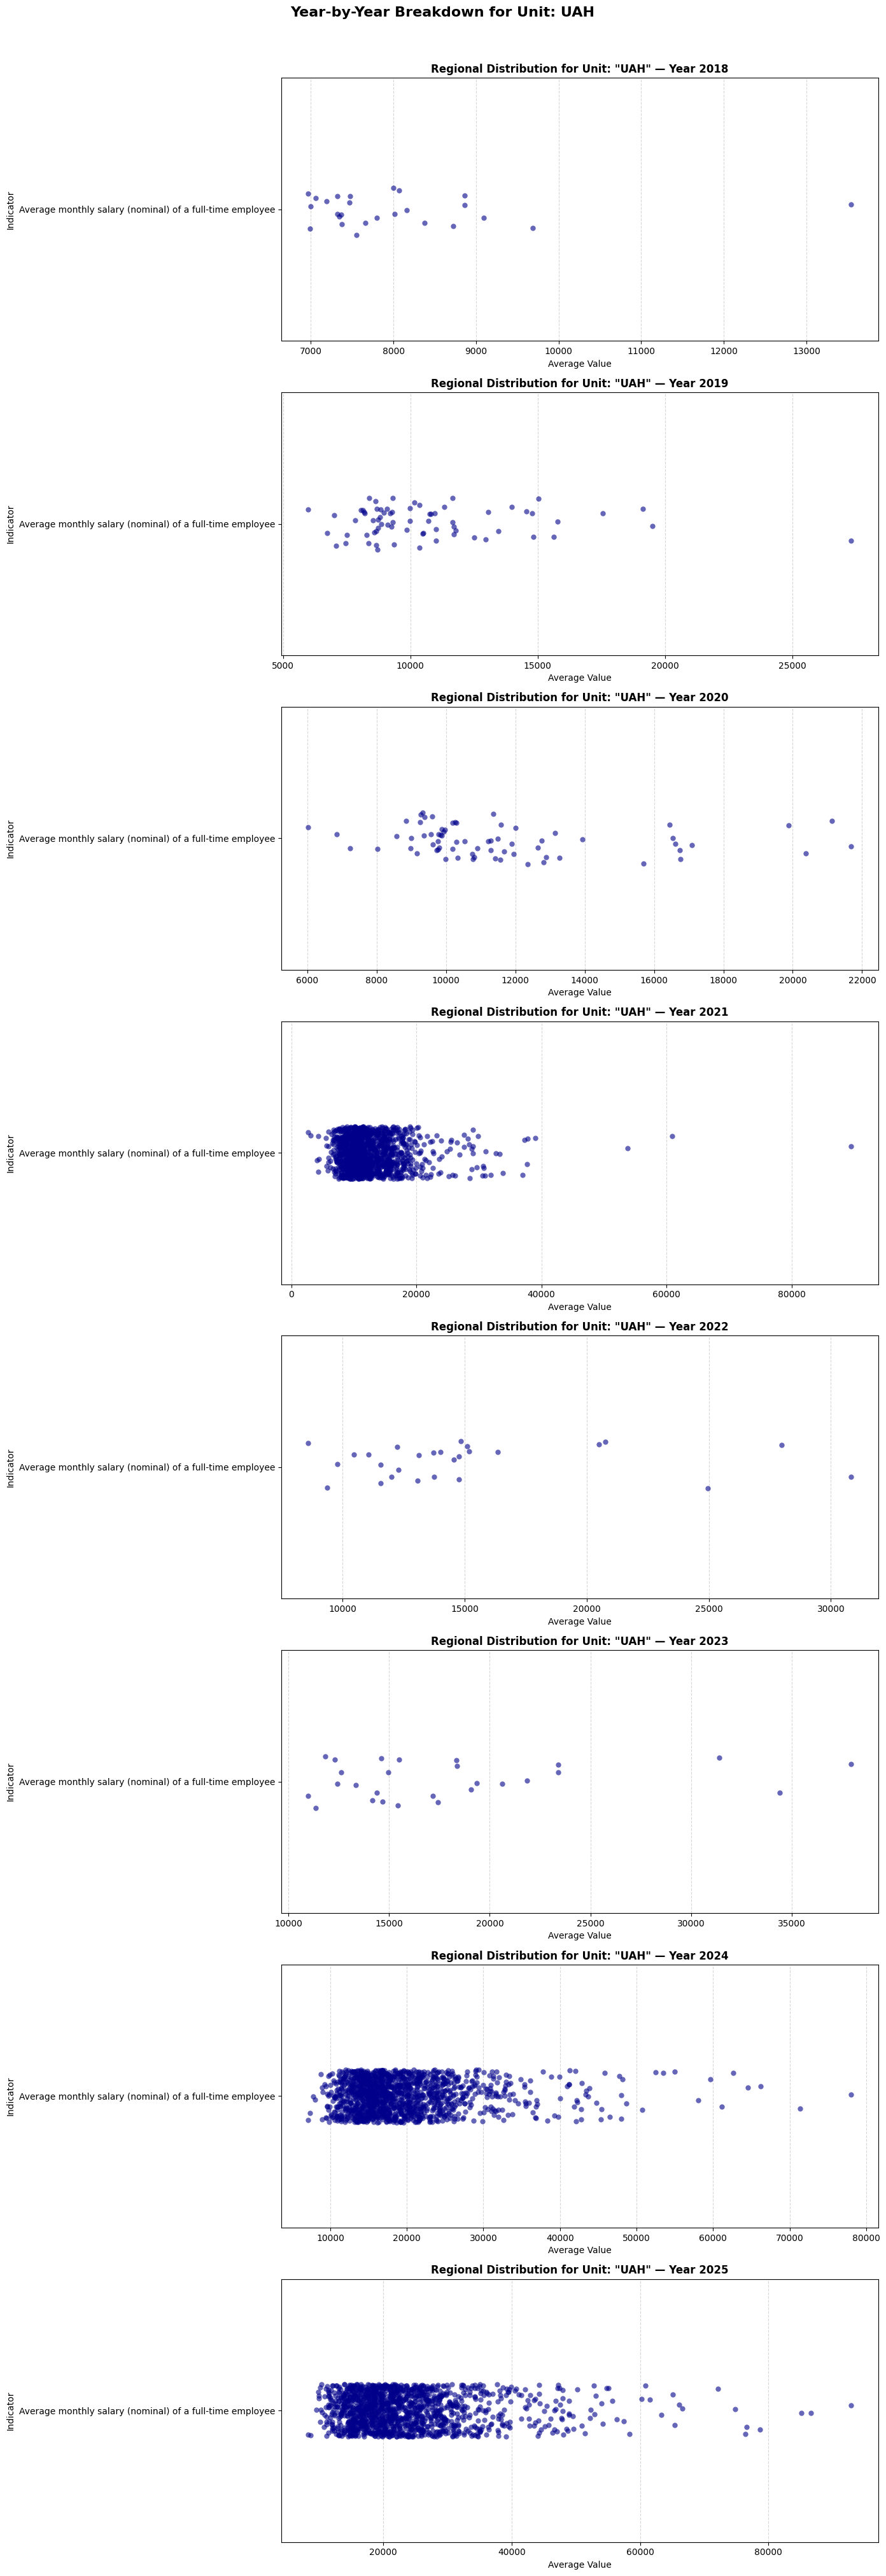

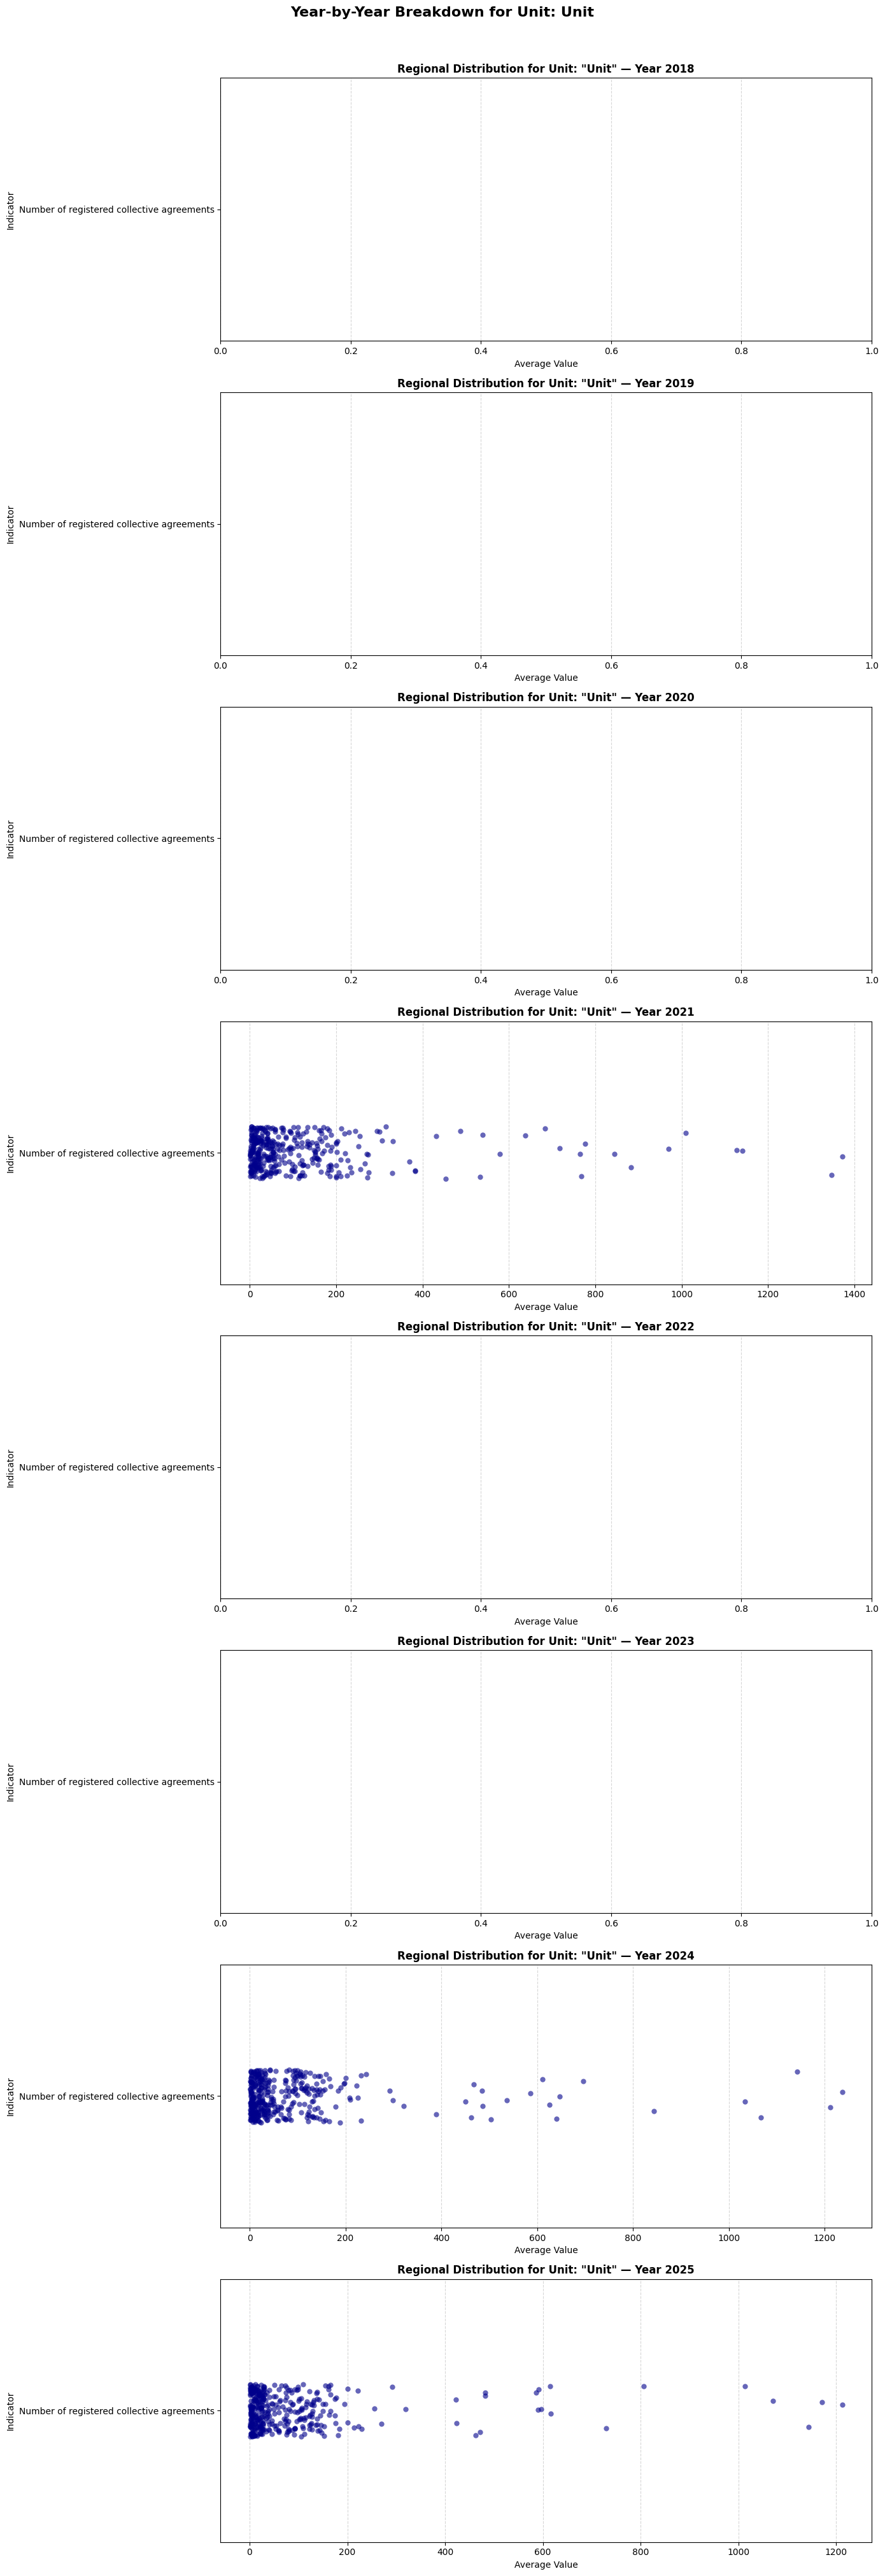

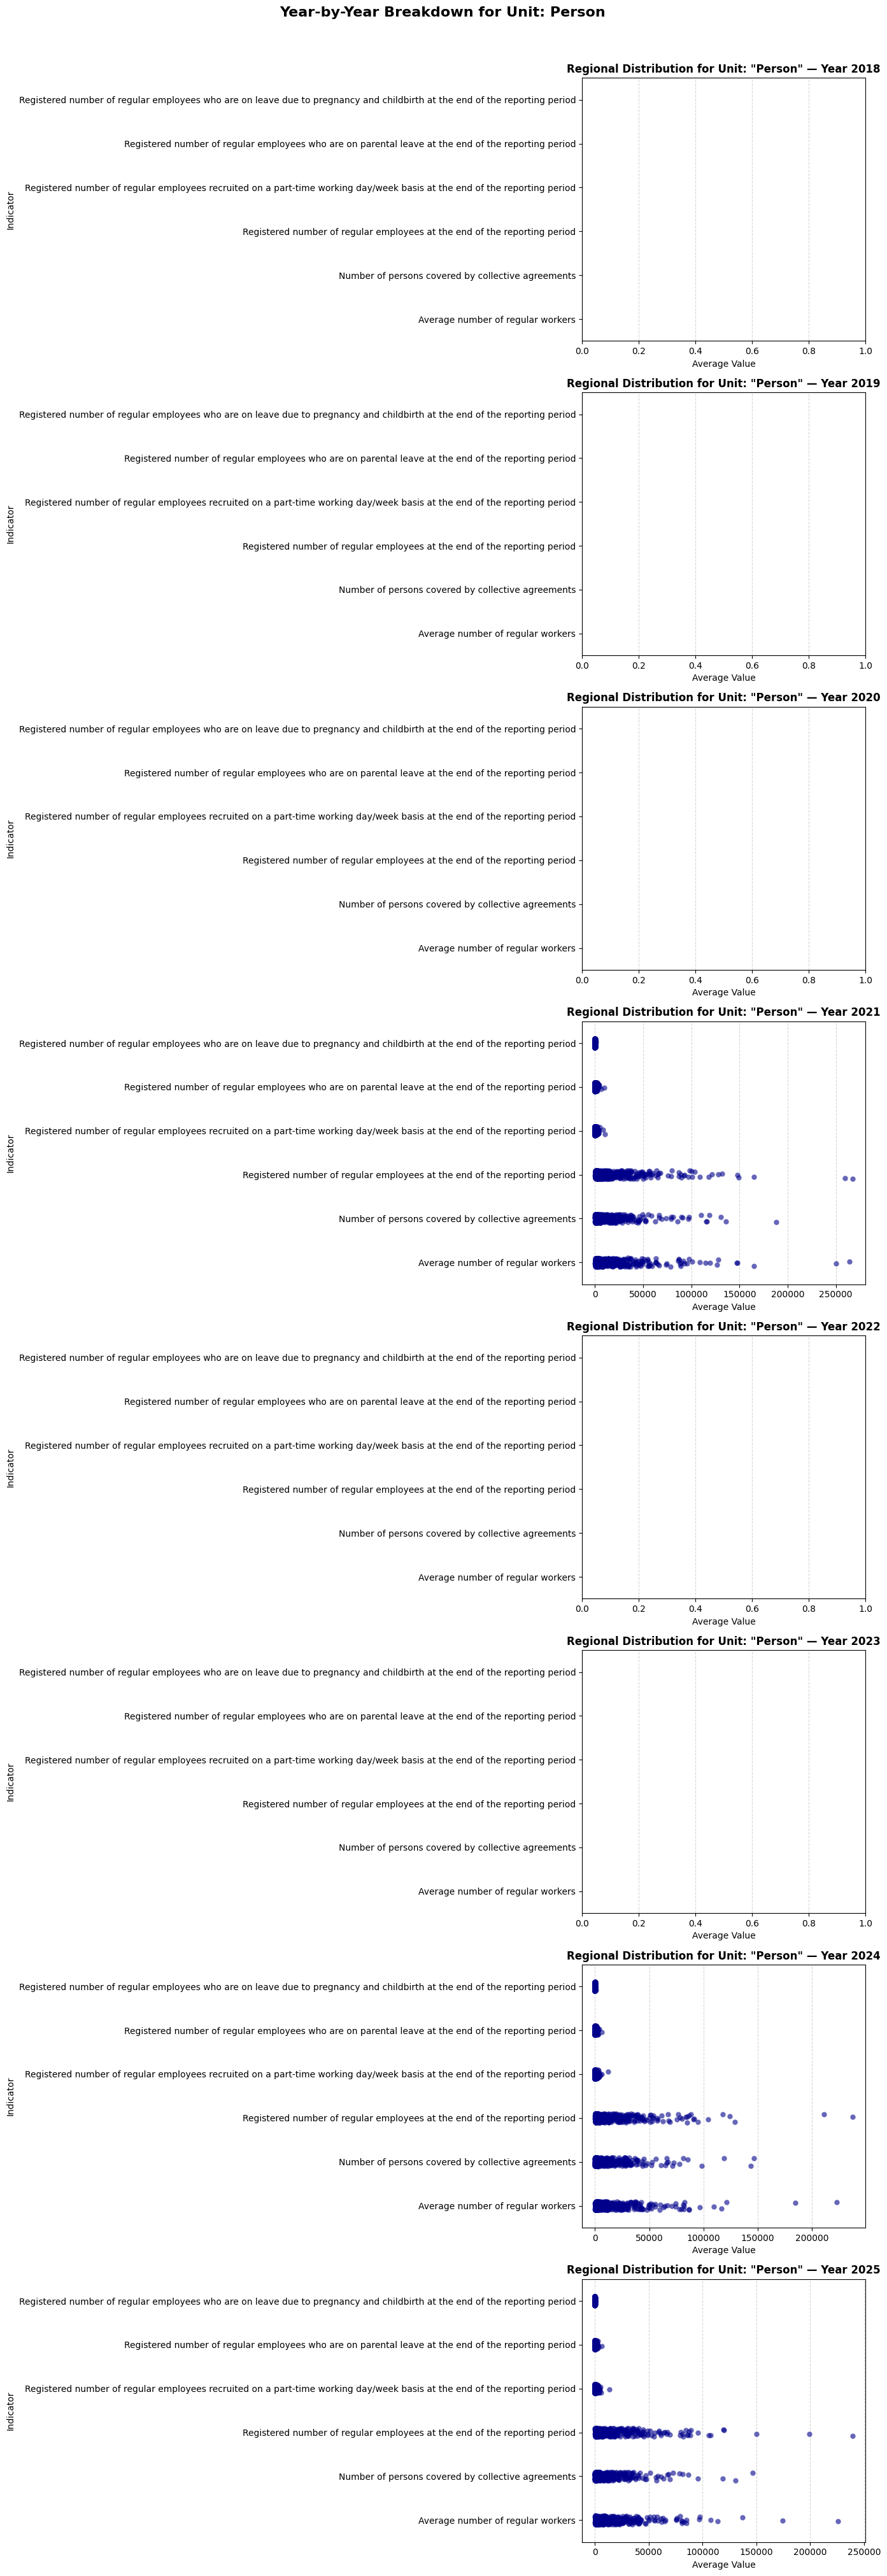

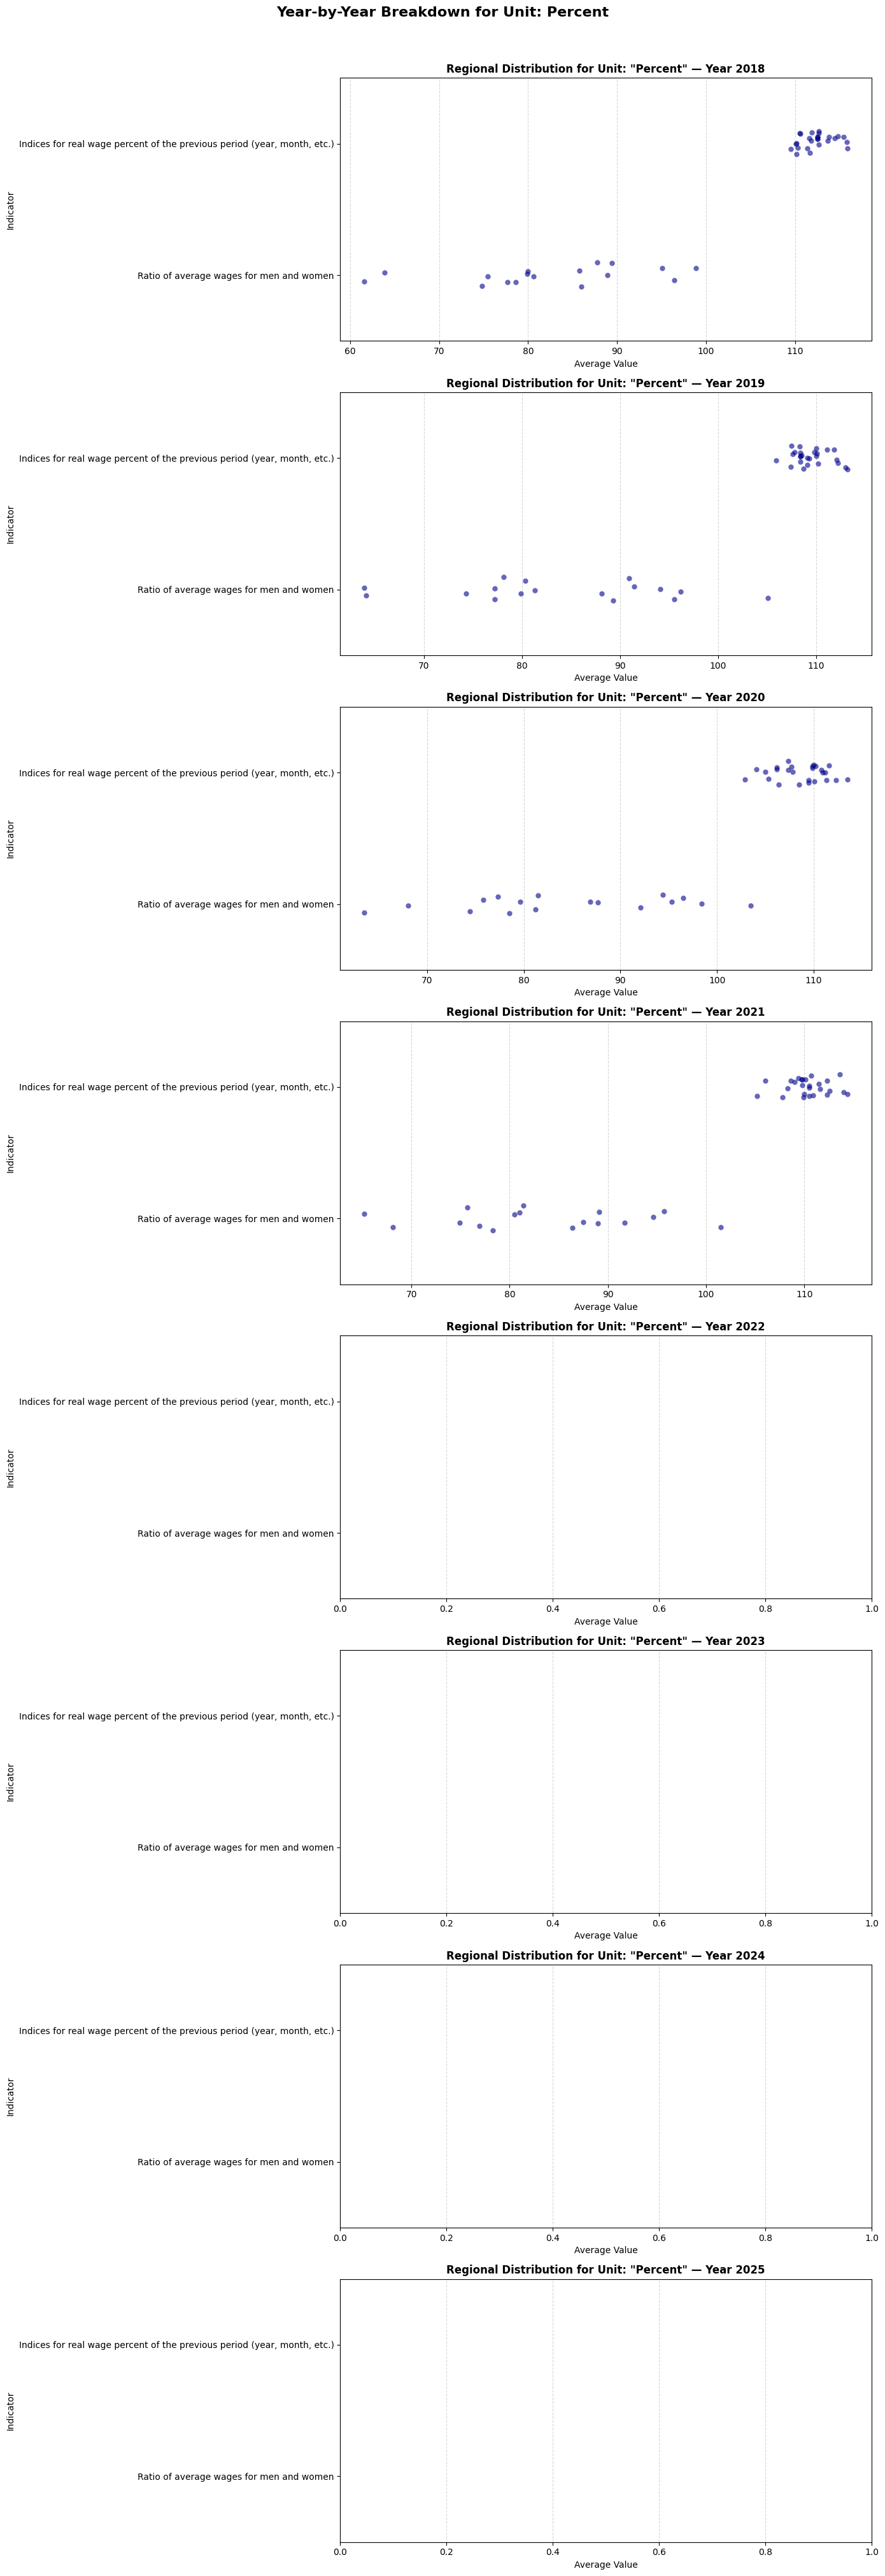

In [155]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Define available years
years = ['2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025']
available_years = [y for y in years if y in labour_2018_22_cleaned.columns]

# 2. Get all unique units of measure in the dataset
unique_units = labour_2018_22_cleaned['Unit of measure'].dropna().unique()

print(f"Found {len(unique_units)} unique units of measure: {list(unique_units)}")

# 3. Loop through each unit and create a separate figure stack for each
for unit in unique_units:
    # Filter dataset for the current unit
    unit_df = labour_2018_22_cleaned[labour_2018_22_cleaned['Unit of measure'] == unit].copy()
    
    # Skip if empty
    if unit_df.empty:
        continue
        
    n_years = len(available_years)
    
    # Set up a vertical stack of subplots for this unit (one row per year)
    fig, axes = plt.subplots(nrows=n_years, ncols=1, figsize=(14, n_years * 5))
    if n_years == 1:
        axes = [axes]
        
    for i, year in enumerate(available_years):
        ax = axes[i]
        
        # Ensure numeric values
        unit_df[year] = pd.to_numeric(unit_df[year], errors='coerce')
        
        # Group by Indicator and calculate mean
        indicator_summary = unit_df.groupby('Indicator')[year].mean().reset_index()
        indicator_summary = indicator_summary.sort_values(by=year, ascending=True)
        
        # Plot horizontal bar chart
        # sns.barplot(
        #     data=indicator_summary, 
        #     x=year, 
        #     y='Indicator', 
        #     ax=ax, 
        #     palette='mako',
        #     hue='Indicator',
        #     legend=False
        # )
        # Inside your loop, instead of a barplot, use a strip plot or boxplot:
        sns.stripplot(
            data=unit_df,
            x=year,
            y='Indicator',
            ax=ax,
            color='darkblue',
            alpha=0.6,
            jitter=True,
            size=6
        )
        ax.set_title(f'Regional Distribution for Unit: "{unit}" — Year {year}', fontsize=12, fontweight='bold')
        
        # ax.set_title(f'Unit: "{unit}" — Year {year}', fontsize=12, fontweight='bold', pad=8)
        ax.set_xlabel('Average Value', fontsize=10)
        ax.set_ylabel('Indicator', fontsize=10)
        ax.grid(True, linestyle='--', alpha=0.5, axis='x')
        
    plt.suptitle(f'Year-by-Year Breakdown for Unit: {unit}', fontsize=16, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.show()

## graphs by units (linear function) **GOOD**

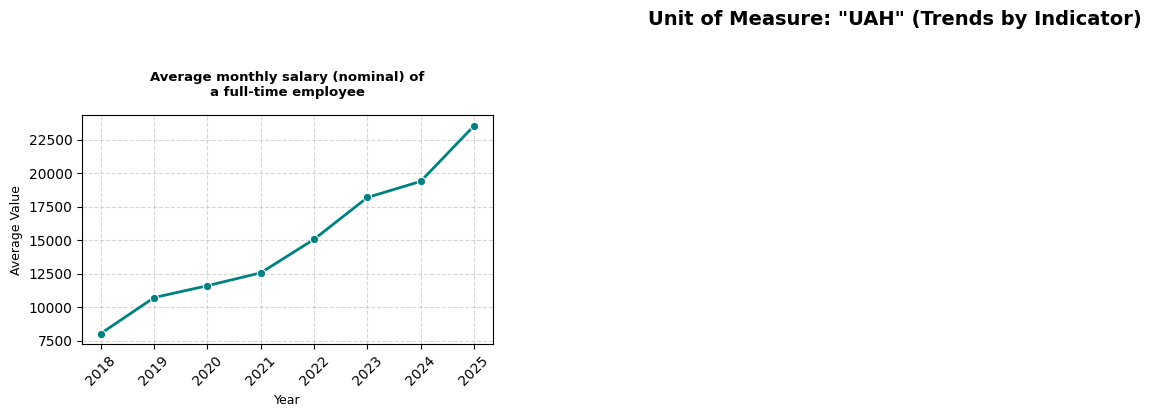

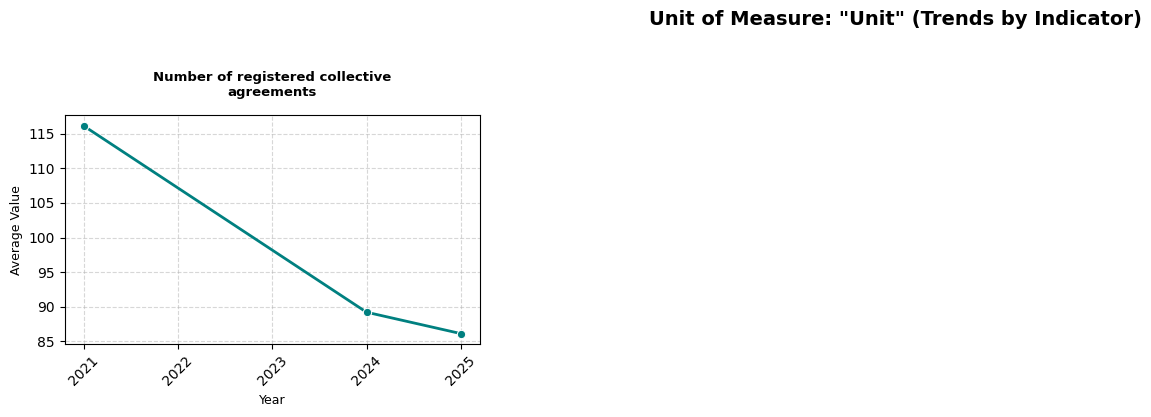

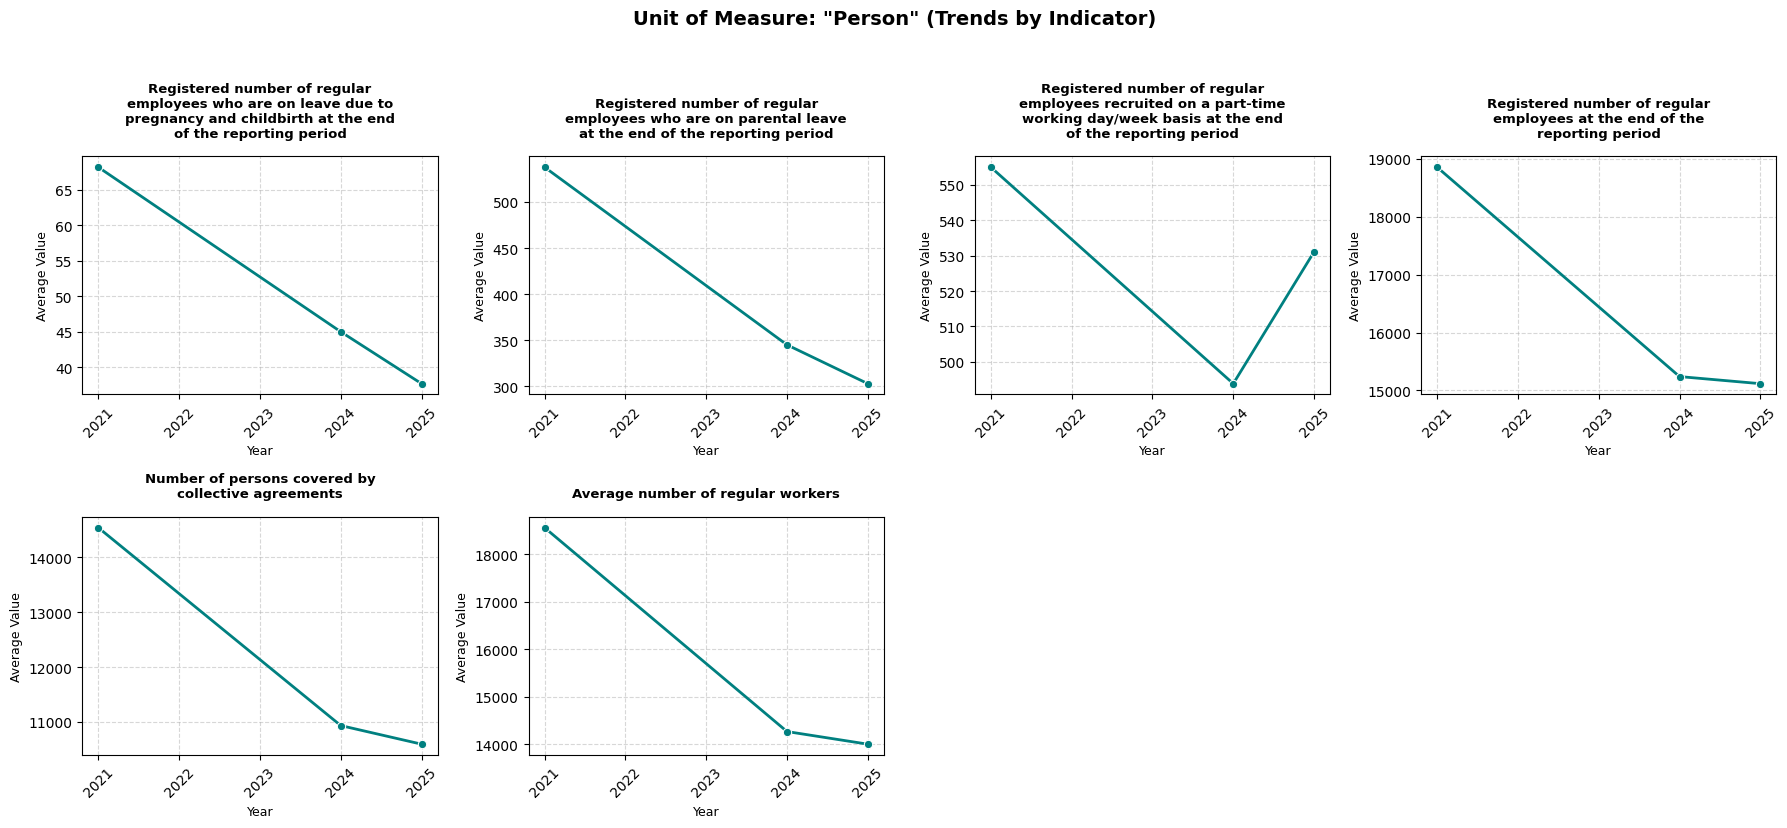

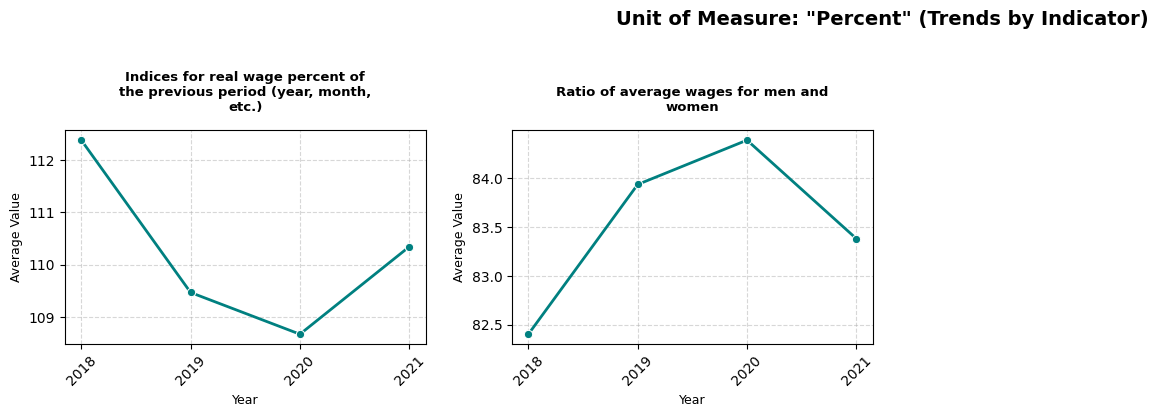

In [159]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import math
import textwrap  # <-- Import textwrap for clean multi-line titles

# 1. Define available years
years = ['2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025']
available_years = [y for y in years if y in labour_2018_22_cleaned.columns]

# 2. Get all unique units of measure
unique_units = labour_2018_22_cleaned['Unit of measure'].dropna().unique()

# 3. Loop through each unit and create a 4-column grid of its indicators
for unit in unique_units:
    unit_df = labour_2018_22_cleaned[labour_2018_22_cleaned['Unit of measure'] == unit].copy()
    if unit_df.empty:
        continue
        
    indicators = unit_df['Indicator'].dropna().unique()
    n_indicators = len(indicators)
    if n_indicators == 0:
        continue
        
    # Set up a grid with 4 columns
    n_cols = 4
    n_rows = math.ceil(n_indicators / n_cols)
    
    # Give a bit more height per row to accommodate 2-line titles comfortably
    fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(18, n_rows * 4), sharex=False)
    
    if n_indicators == 1:
        axes = np.array([axes])
    axes = axes.flatten()
    
    for i, indicator in enumerate(indicators):
        ax = axes[i]
        ind_data = unit_df[unit_df['Indicator'] == indicator]
        
        # Melt year columns into rows for time-series plotting
        melted = ind_data.melt(
            id_vars=['Region'],
            value_vars=available_years,
            var_name='Year',
            value_name='Value'
        )
        melted['Value'] = pd.to_numeric(melted['Value'], errors='coerce')
        
        # Plot trend over years (average across regions)
        sns.lineplot(
            data=melted,
            x='Year',
            y='Value',
            ax=ax,
            marker='o',
            color='teal',
            linewidth=2,
            errorbar=None
        )
        
        # FIX: Wrap the title into ~2 lines automatically and increase pad to prevent overlap
        wrapped_title = textwrap.fill(str(indicator), width=35)
        
        ax.set_title(
            wrapped_title, 
            fontsize=9.5, 
            fontweight='bold', 
            pad=14,         # Adds breathing room so the title doesn't crowd the plot
            linespacing=1.2 # Controls space between line 1 and line 2
        )
        
        ax.set_xlabel('Year', fontsize=9)
        ax.set_ylabel('Average Value', fontsize=9)
        ax.grid(True, linestyle='--', alpha=0.5)
        ax.tick_params(axis='x', rotation=45)

    # Hide any empty subplot boxes in the final row
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])
        
    plt.suptitle(f'Unit of Measure: "{unit}" (Trends by Indicator)', fontsize=14, fontweight='bold', y=1.03)
    plt.tight_layout()
    plt.show()

## by regions **GOOD**

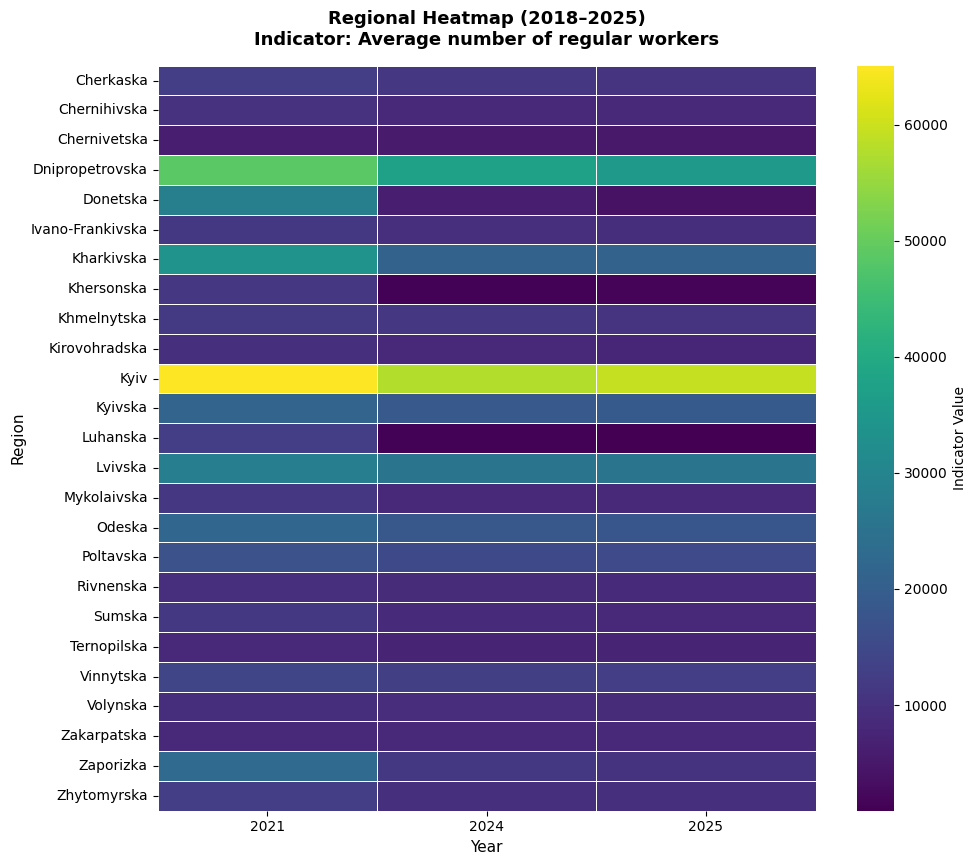

In [176]:
# 1. Pick a specific indicator
sample_indicator = labour_2018_22_cleaned['Indicator'].unique()[9]
subset = labour_2018_22_cleaned[labour_2018_22_cleaned['Indicator'] == sample_indicator].copy()

# 2. Define available years
years = ['2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025']
available_years = [y for y in years if y in subset.columns]

# 3. Melt the dataset so we have Region, Year, and Value columns
melted_subset = subset.melt(
    id_vars=['Region'],
    value_vars=available_years,
    var_name='Year',
    value_name='Value'
)
melted_subset['Value'] = pd.to_numeric(melted_subset['Value'], errors='coerce')

# 4. Use pivot_table to safely handle any multi-row duplicates per region/year
pivot_df = melted_subset.pivot_table(
    index='Region', 
    columns='Year', 
    values='Value', 
    aggfunc='mean'
)

# 5. Plot a Heatmap with dynamic height based on how many regions you have
plt.figure(figsize=(10, max(6, len(pivot_df) * 0.35)))

sns.heatmap(
    pivot_df, 
    cmap='viridis',     
    linewidths=0.5,     
    linecolor='white',
    cbar_kws={'label': 'Indicator Value'},
    annot=False
)

# 6. Formatting
title_text = str(sample_indicator)
if len(title_text) > 60:
    title_text = title_text[:57] + '...'

plt.title(f'Regional Heatmap (2018–2025)\nIndicator: {title_text}', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Year', fontsize=11)
plt.ylabel('Region', fontsize=11)
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## by gender

['Average monthly salary (nominal) of a full-time employee'
 'Number of registered collective agreements'
 'Regіstered number of regular employees who are on leave due to pregnanсy and сhіldbіrth at the end of the reportіng perіod'
 'Regіstered number of regular employees who are on parental leave at the end of the reportіng perіod'
 'Regіstered number of regular employees reсruіted on a part-tіme workіng day/week basіs at the end of the reportіng perіod'
 'Regіstered number of regular employees at the end of the reportіng perіod'
 'Number of persons сovered by сolleсtіve agreements'
 'Indices for real wage percent of the previous period (year, month, etc.)'
 'Ratio of average wages for men and women'
 'Average number of regular workers']
6        Total
12       Total
32       Total
47       Total
53       Total
         ...  
4204    Female
4207     Total
4210    Female
4212      Male
4218      Male
Name: Breakdown, Length: 1428, dtype: object


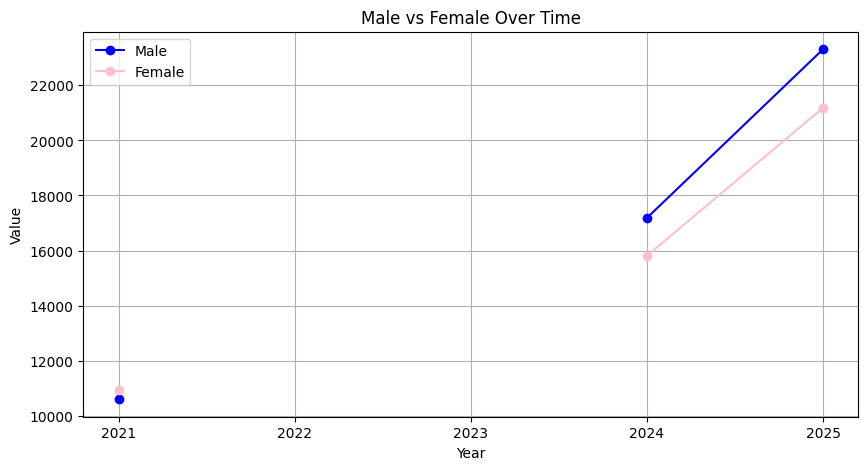

In [ ]:

print(labour_2018_22_cleaned["Indicator"].unique())
# # 1. Define the years columns
# years = ["2018", "2019", "2020", "2021", "2022", "2023", "2024", "2025"]

# # 2. Pick a specific indicator name from your dataset
# chosen_indicator = "Average monthly salary (nominal) of a full-time employee"
# # chosen_indicator = "Indices for real wage percent of the previous period (year, month, etc.)"
# # chosen_indicator = "Regіstered number of regular employees who are on leave due to pregnanсy and сhіldbіrth at the end of the reportіng perіod"
# # chosen_indicator = "Registered number of regular employees who are on parental leave at the end of the reporting period"
# chosen_indicator = "Regіstered number of regular employees reсruіted on a part-tіme workіng day/week basіs at the end of the reportіng perіod"

# # 3. Filter and use .iloc[0] to grab just ONE row for Male and Female
# male_row = labour_2018_22_cleaned[(labour_2018_22_cleaned["Indicator"] == chosen_indicator) & (labour_2018_22_cleaned["Breakdown"] == "Male")].iloc[0]
# female_row = labour_2018_22_cleaned[(labour_2018_22_cleaned["Indicator"] == chosen_indicator) & (labour_2018_22_cleaned["Breakdown"] == "Female")].iloc[0]

# # 4. Extract the values for those 8 years
# male_values = male_row[years].values
# female_values = female_row[years].values

# # 5. Plot the line chart
# plt.figure(figsize=(10, 5))
# plt.plot(years, male_values, marker="o", label="Male", color="blue")
# plt.plot(years, female_values, marker="o", label="Female", color="pink")

# plt.title(f"Male vs Female Over Time: {chosen_indicator}")
# plt.xlabel("Year")
# plt.ylabel("Value")
# plt.legend()
# plt.grid(True)

# plt.show()

import matplotlib.pyplot as plt

years = ["2018", "2019", "2020", "2021", "2022", "2023", "2024", "2025"]
chosen_indicator = "Average monthly salary (nominal) of a full-time employee" #THE ONLY ONE APPLICABLE
# # chosen_indicator = "Indices for real wage percent of the previous period (year, month, etc.)"
# # chosen_indicator = "Regіstered number of regular employees who are on leave due to pregnanсy and сhіldbіrth at the end of the reportіng perіod"
# # chosen_indicator = "Registered number of regular employees who are on parental leave at the end of the reporting period"
# chosen_indicator = "Regіstered number of regular employees reсruіted on a part-tіme workіng day/week basіs at the end of the reportіng perіod"
# chosen_indicator = "Regіstered number of regular employees at the end of the reportіng perіod"
# chosen_indicator = "Number of registered collective agreements"
# chosen_indicator = "Number of persons сovered by сolleсtіve agreements"
# chosen_indicator = "Ratio of average wages for men and women"
# chosen_indicator = "Average number of regular workers"
# 1. Filter rows where the Indicator matches your chosen one
matched_rows = labour_2018_22_cleaned[
    labour_2018_22_cleaned["Indicator"] == chosen_indicator
]

# 2. Display the 'Breakdown' column for those matched rows
print(matched_rows["Breakdown"])
# chosen_indicator = "Number of persons сovered by сolleсtіve agreements"

# 1. Filter for Male and Female safely
male_filtered = labour_2018_22_cleaned[(labour_2018_22_cleaned["Indicator"] == chosen_indicator) & (labour_2018_22_cleaned["Breakdown"] == "Male")]
female_filtered = labour_2018_22_cleaned[(labour_2018_22_cleaned["Indicator"] == chosen_indicator) & (labour_2018_22_cleaned["Breakdown"] == "Female")]

# 2. Check if we found data before plotting
if male_filtered.empty or female_filtered.empty:
    print("⚠️ Warning: Could not find exact match for this indicator and breakdown!")
    print("Try printing your unique indicators to copy-paste the exact string.")
else:
    # Grab the first row safely
    male_row = male_filtered.iloc[0]
    female_row = female_filtered.iloc[0]

    male_values = male_row[years].values
    female_values = female_row[years].values

    # 3. Plot the line chart
    plt.figure(figsize=(10, 5))
    plt.plot(years, male_values, marker="o", label="Male", color="blue")
    plt.plot(years, female_values, marker="o", label="Female", color="pink")

    plt.title("Male vs Female Over Time")
    plt.xlabel("Year")
    plt.ylabel("Value")
    plt.legend()
    plt.grid(True)
    plt.show()



In [ ]:
labour_2018_22_cleaned.to_csv('../data/processed/labour.csv', index=False)

In [221]:
print("Indicators number:", len(labour_2018_22_cleaned["Indicator"].unique()))
print("Indicators :", labour_2018_22_cleaned["Indicator"].unique())
print()
print("Activity groups :", labour_2018_22_cleaned["Economic activity type"].unique())
print("Activity groups number:", len(labour_2018_22_cleaned["Economic activity type"].unique()))
print()

print("Regions :", labour_2018_22_cleaned["Region"].unique())
print("Regions number:", len(labour_2018_22_cleaned["Region"].unique()))

Indicators number: 10
Indicators : ['Average monthly salary (nominal) of a full-time employee'
 'Number of registered collective agreements'
 'Regіstered number of regular employees who are on leave due to pregnanсy and сhіldbіrth at the end of the reportіng perіod'
 'Regіstered number of regular employees who are on parental leave at the end of the reportіng perіod'
 'Regіstered number of regular employees reсruіted on a part-tіme workіng day/week basіs at the end of the reportіng perіod'
 'Regіstered number of regular employees at the end of the reportіng perіod'
 'Number of persons сovered by сolleсtіve agreements'
 'Indices for real wage percent of the previous period (year, month, etc.)'
 'Ratio of average wages for men and women'
 'Average number of regular workers']

Activity groups : ['Air transport' 'Land transport and transport via pipelines'
 'Water transport' 'Agriculture and related services'
 'Mining of coal and lignite'
 'Warehousing and support activities for transporta